# Week 11 — A: retrieval

SAFE BY DEFAULT. Run All loads saved real results if present; otherwise it uses fabricated smoke fixtures (H/I read saved results only). No datasets/models are downloaded automatically. QASPER TEST is blocked.

For a user full run: set `RUN_FULL=True` and `RUN_SMOKE=False` in the next cell. Every later setup is derived automatically. Existing validated rows are reused. `OVERWRITE=True` is deliberately unsupported.



In [1]:
RUN_SMOKE = False
RUN_FULL = True
RESUME = True
OVERWRITE = False
RUN_A_SMOKE = RUN_SMOKE
RUN_A_FULL = RUN_FULL
SMOKE_LIMIT = 3
REVIEW_PHASE = None
REVIEWED_CONFIG = None
REVIEW_REASON = None


In [2]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
while not (ROOT/'src/week11').is_dir():
    if ROOT == ROOT.parent: raise FileNotFoundError('Open inside CS787-RAG-Project')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.week11.protocol import load, review
from src.week11.runner import execute, notebook_smoke
from src.week11.dashboard import status, resources
cfg = load()
pd.set_option('display.max_columns', 24)
pd.set_option('display.max_colwidth', 70)
configuration_df = pd.DataFrame([{'setting': k, 'value': str(v)} for k,v in cfg.items()])
display(configuration_df)
run_status_df = status(cfg)
display(run_status_df)
display(resources(cfg))


/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,setting,value
0,version,v1
1,output_root,results/week11/multigranular/v1
2,cache_root,cache/week11/v1
3,verification_dataset,SciFact
4,primary_reader,Qwen
5,seed,42
6,epsilon,0.01
7,bootstrap_resamples,10000
8,characterization_queries_per_dataset,50
9,query_sampling,"sha256(dataset,query_id,seed), independent of labels"


,phase,notebook,full_status,number_expected,number_completed,result_path,next_action,freeze_exists
0,0,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,150.0,150,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
1,A,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,1350.0,1350,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
2,B,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,600.0,600,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
3,C,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE_ELIGIBLE_PENDING_OPTIONAL,5550.0,5550,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,False
4,D,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
5,E,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
6,F,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
7,G,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
8,H,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
9,I,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False


,phase,dataset,configured_queries,planned_configurations,executable_configurations,pending_configurations,answer_rows_upper_bound,executable_answer_rows_upper_bound,new_lm_calls,actual_time_estimate
0,0,QASPER,50,0,0,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
1,0,HotpotQA,50,0,0,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
2,0,SciFact,50,0,0,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
3,A,QASPER,50,9,9,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
4,A,HotpotQA,50,9,9,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
5,A,SciFact,50,9,9,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
6,B,QASPER,50,4,4,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
7,B,HotpotQA,50,4,4,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
8,B,SciFact,50,4,4,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
9,C,QASPER,50,41,37,4,2050,1850,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured


## Execute or resume

Synthetic output is stored only under `smoke/`. Pending token-compressor conditions are reported explicitly, never filled with invented scores. Full dependent phases require the previous manual freeze.

In [3]:
if OVERWRITE: raise ValueError('Immutable results: use a new output version instead of overwrite')
if not RESUME: raise ValueError('Resume stays enabled; new experiments require a new configured version')
effective_smoke = notebook_smoke(cfg, 'A', RUN_SMOKE, RUN_FULL)
frames, figures = execute('A', cfg, full=RUN_FULL, explicit=RUN_FULL, smoke=effective_smoke, limit=SMOKE_LIMIT)
print('SYNTHETIC SMOKE ONLY' if effective_smoke else 'Saved/full result tables; inspect status before review')
display(frames.get('condition_status_df', pd.DataFrame()))


W11-A retrieval: 100%|██████████| 150/150 [00:15<00:00,  9.65it/s]


Saved/full result tables; inspect status before review


""


### retrieval_summary_df

In [4]:
retrieval_summary_df = frames.get('retrieval_summary_df', pd.DataFrame())
display(retrieval_summary_df)

,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,25.025793,1.0,0.00,0.72,NaN,...,2.66,0.811524,NaN,30.16,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
1,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,25.025793,2.0,0.12,0.82,0.883061,...,2.66,0.811524,0.116939,64.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
2,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,25.025793,4.0,0.36,0.92,0.888660,...,2.66,0.811524,0.111340,123.36,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
3,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,25.025793,6.0,0.52,0.96,0.903035,...,2.66,0.811524,0.096965,182.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
4,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,25.025793,8.0,0.62,0.98,0.904230,...,2.66,0.811524,0.095770,244.04,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,2,NaN,33.421023,2.0,0.44,0.60,0.887871,...,0.80,0.498946,0.112129,63.08,0.0,0.339290,NaN,NaN,NaN,NaN,50,25
158,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,4,NaN,33.421023,4.0,0.48,0.68,0.905312,...,0.80,0.498946,0.094688,128.26,0.0,0.339290,NaN,NaN,NaN,NaN,50,25
159,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,6,NaN,33.421023,6.0,0.48,0.72,0.907506,...,0.80,0.498946,0.092494,187.22,0.0,0.339290,NaN,NaN,NaN,NaN,50,25
160,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,8,NaN,33.421023,8.0,0.52,0.72,0.912054,...,0.80,0.498946,0.087946,248.00,0.0,0.339290,NaN,NaN,NaN,NaN,50,25


### recall_at_k_df

In [5]:
recall_at_k_df = frames.get('recall_at_k_df', pd.DataFrame())
display(recall_at_k_df)

,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,1,0.0,...,1,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,NaN,34,0,[56c9ad5facead84a1c21492b36f7fcd2],0.000284,NaN,NaN,NaN,NaN
1,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.121212,62,0,"[56c9ad5facead84a1c21492b36f7fcd2, c426f3b9aef0adad127ce9a0922a5c89]",0.000284,NaN,NaN,NaN,NaN
2,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.107842,121,0,"[56c9ad5facead84a1c21492b36f7fcd2, c426f3b9aef0adad127ce9a0922a5c8...",0.000284,NaN,NaN,NaN,NaN
3,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,6,0.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.113762,200,0,"[56c9ad5facead84a1c21492b36f7fcd2, c426f3b9aef0adad127ce9a0922a5c8...",0.000284,NaN,NaN,NaN,NaN
4,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,8,0.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.127121,288,0,"[56c9ad5facead84a1c21492b36f7fcd2, c426f3b9aef0adad127ce9a0922a5c8...",0.000284,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8095,69361abe8d8c0d1d61a8,544,SciFact,SENTENCE,NaN,33.421023,P0,544,SFR,False,2,NaN,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.086957,97,0,"[9a87faafcbe97c0dc49d8ed2ac4a8339, 1428bc63b75c7957470e574a95f84d04]",2.487707,2118.681556,1.771873,0.057921,0.001388
8096,69361abe8d8c0d1d61a8,544,SciFact,SENTENCE,NaN,33.421023,P0,544,SFR,False,4,NaN,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.068812,193,0,"[9a87faafcbe97c0dc49d8ed2ac4a8339, 1428bc63b75c7957470e574a95f84d0...",2.487707,2118.681556,1.771873,0.057921,0.001388
8097,69361abe8d8c0d1d61a8,544,SciFact,SENTENCE,NaN,33.421023,P0,544,SFR,False,6,NaN,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.083434,266,0,"[9a87faafcbe97c0dc49d8ed2ac4a8339, 1428bc63b75c7957470e574a95f84d0...",2.487707,2118.681556,1.771873,0.057921,0.001388
8098,69361abe8d8c0d1d61a8,544,SciFact,SENTENCE,NaN,33.421023,P0,544,SFR,False,8,NaN,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.077652,357,0,"[9a87faafcbe97c0dc49d8ed2ac4a8339, 1428bc63b75c7957470e574a95f84d0...",2.487707,2118.681556,1.771873,0.057921,0.001388


### evidence_coverage_df

In [6]:
evidence_coverage_df = frames.get('evidence_coverage_df', pd.DataFrame())
display(evidence_coverage_df)

,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,25.025793,1.0,0.00,0.72,NaN,...,2.66,0.811524,NaN,30.16,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
1,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,25.025793,2.0,0.12,0.82,0.883061,...,2.66,0.811524,0.116939,64.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
2,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,25.025793,4.0,0.36,0.92,0.888660,...,2.66,0.811524,0.111340,123.36,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
3,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,25.025793,6.0,0.52,0.96,0.903035,...,2.66,0.811524,0.096965,182.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
4,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,25.025793,8.0,0.62,0.98,0.904230,...,2.66,0.811524,0.095770,244.04,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,2,NaN,33.421023,2.0,0.44,0.60,0.887871,...,0.80,0.498946,0.112129,63.08,0.0,0.339290,NaN,NaN,NaN,NaN,50,25
158,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,4,NaN,33.421023,4.0,0.48,0.68,0.905312,...,0.80,0.498946,0.094688,128.26,0.0,0.339290,NaN,NaN,NaN,NaN,50,25
159,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,6,NaN,33.421023,6.0,0.48,0.72,0.907506,...,0.80,0.498946,0.092494,187.22,0.0,0.339290,NaN,NaN,NaN,NaN,50,25
160,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,8,NaN,33.421023,8.0,0.52,0.72,0.912054,...,0.80,0.498946,0.087946,248.00,0.0,0.339290,NaN,NaN,NaN,NaN,50,25


### retrieval_cost_df

In [7]:
retrieval_cost_df = frames.get('retrieval_cost_df', pd.DataFrame())
display(retrieval_cost_df)

,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,25.025793,1.0,0.00,0.72,NaN,...,2.66,0.811524,NaN,30.16,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
1,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,25.025793,2.0,0.12,0.82,0.883061,...,2.66,0.811524,0.116939,64.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
2,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,25.025793,4.0,0.36,0.92,0.888660,...,2.66,0.811524,0.111340,123.36,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
3,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,25.025793,6.0,0.52,0.96,0.903035,...,2.66,0.811524,0.096965,182.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
4,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,25.025793,8.0,0.62,0.98,0.904230,...,2.66,0.811524,0.095770,244.04,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,2,NaN,33.421023,2.0,0.44,0.60,0.887871,...,0.80,0.498946,0.112129,63.08,0.0,0.339290,NaN,NaN,NaN,NaN,50,25
158,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,4,NaN,33.421023,4.0,0.48,0.68,0.905312,...,0.80,0.498946,0.094688,128.26,0.0,0.339290,NaN,NaN,NaN,NaN,50,25
159,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,6,NaN,33.421023,6.0,0.48,0.72,0.907506,...,0.80,0.498946,0.092494,187.22,0.0,0.339290,NaN,NaN,NaN,NaN,50,25
160,SciFact,bd4f9f7b6db5f1cc0603,BM25,SENTENCE,P0,8,NaN,33.421023,8.0,0.52,0.72,0.912054,...,0.80,0.498946,0.087946,248.00,0.0,0.339290,NaN,NaN,NaN,NaN,50,25


### retrieval_pairwise_df

In [8]:
retrieval_pairwise_df = frames.get('retrieval_pairwise_df', pd.DataFrame())
display(retrieval_pairwise_df)

,dataset,action_a,action_b,metric,family,point,ci_low,ci_high,resamples,seed,cluster
0,HotpotQA,08eeaf51742df28d788e,55db50b68b85b4157276,evidence_coverage,primary,0.253094,1.708140e-01,0.338664,10000,42,query_or_claim_id
1,HotpotQA,0bc6111c85ee7f5f4a69,a8796bc19b94cdb8f5c3,evidence_coverage,primary,0.076667,-2.220446e-18,0.153333,10000,42,query_or_claim_id
2,HotpotQA,43db754dc48ca3463c07,bd4f9f7b6db5f1cc0603,evidence_coverage,primary,0.045833,-4.016667e-02,0.134504,10000,42,query_or_claim_id
3,HotpotQA,69361abe8d8c0d1d61a8,bd4f9f7b6db5f1cc0603,evidence_coverage,primary,0.236333,1.523333e-01,0.322008,10000,42,query_or_claim_id
4,HotpotQA,a5ccd1b17003da385cf5,55db50b68b85b4157276,evidence_coverage,primary,0.033944,-5.277184e-02,0.121845,10000,42,query_or_claim_id
5,HotpotQA,aacff50085079bad87b8,a8796bc19b94cdb8f5c3,evidence_coverage,primary,0.143333,7.000000e-02,0.220000,10000,42,query_or_claim_id
6,QASPER,08eeaf51742df28d788e,55db50b68b85b4157276,evidence_coverage,primary,0.078174,1.723029e-02,0.138888,10000,42,paper_id
7,QASPER,0bc6111c85ee7f5f4a69,a8796bc19b94cdb8f5c3,evidence_coverage,primary,-0.015077,-1.548331e-01,0.121089,10000,42,paper_id
8,QASPER,43db754dc48ca3463c07,bd4f9f7b6db5f1cc0603,evidence_coverage,primary,0.006242,-4.409548e-02,0.058857,10000,42,paper_id
9,QASPER,69361abe8d8c0d1d61a8,bd4f9f7b6db5f1cc0603,evidence_coverage,primary,0.076628,1.543028e-02,0.137720,10000,42,paper_id


## Figures and underlying tables

Each PNG/PDF has a source CSV. Different datasets are plotted separately; cross-dataset displays use ranks/counts.

recall_curves HotpotQA / PASSAGE


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,aacff50085079bad87b8,5ae72fc5554299572ea54770,HotpotQA,PASSAGE,123.5,123.5,P0,5ae72fc5554299572ea54770,SFR,False,1,0.0,...,1,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,NaN,76,0,['5c2b263541bb74f3a7370dd911611ca9'],0.651817,0.568126,0.606041,0.041559,0.045326
1,aacff50085079bad87b8,5ae72fc5554299572ea54770,HotpotQA,PASSAGE,123.5,123.5,P0,5ae72fc5554299572ea54770,SFR,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.558824,141,0,"['5c2b263541bb74f3a7370dd911611ca9', '87a104a40c9b2aecc641ed094a96...",0.651817,0.568126,0.606041,0.041559,0.045326
2,aacff50085079bad87b8,5ae72fc5554299572ea54770,HotpotQA,PASSAGE,123.5,123.5,P0,5ae72fc5554299572ea54770,SFR,False,4,1.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.234389,431,0,"['5c2b263541bb74f3a7370dd911611ca9', '87a104a40c9b2aecc641ed094a96...",0.651817,0.568126,0.606041,0.041559,0.045326
3,aacff50085079bad87b8,5ae72fc5554299572ea54770,HotpotQA,PASSAGE,123.5,123.5,P0,5ae72fc5554299572ea54770,SFR,False,6,1.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.199435,769,0,"['5c2b263541bb74f3a7370dd911611ca9', '87a104a40c9b2aecc641ed094a96...",0.651817,0.568126,0.606041,0.041559,0.045326
4,aacff50085079bad87b8,5ae72fc5554299572ea54770,HotpotQA,PASSAGE,123.5,123.5,P0,5ae72fc5554299572ea54770,SFR,False,8,1.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.251637,995,0,"['5c2b263541bb74f3a7370dd911611ca9', '87a104a40c9b2aecc641ed094a96...",0.651817,0.568126,0.606041,0.041559,0.045326
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,0bc6111c85ee7f5f4a69,5ae122465542997b2ef7d0f4,HotpotQA,PASSAGE,98.2,98.2,P0,5ae122465542997b2ef7d0f4,MiniLM,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.325581,130,0,"['905d1877aef1fa3ad14ea152f3d90bbe', 'eec31891255210a54351cd12313c...",0.159463,0.115093,0.149977,0.006618,0.009357
896,0bc6111c85ee7f5f4a69,5ae122465542997b2ef7d0f4,HotpotQA,PASSAGE,98.2,98.2,P0,5ae122465542997b2ef7d0f4,MiniLM,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.197088,381,0,"['905d1877aef1fa3ad14ea152f3d90bbe', 'eec31891255210a54351cd12313c...",0.159463,0.115093,0.149977,0.006618,0.009357
897,0bc6111c85ee7f5f4a69,5ae122465542997b2ef7d0f4,HotpotQA,PASSAGE,98.2,98.2,P0,5ae122465542997b2ef7d0f4,MiniLM,False,6,0.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.140472,558,0,"['905d1877aef1fa3ad14ea152f3d90bbe', 'eec31891255210a54351cd12313c...",0.159463,0.115093,0.149977,0.006618,0.009357
898,0bc6111c85ee7f5f4a69,5ae122465542997b2ef7d0f4,HotpotQA,PASSAGE,98.2,98.2,P0,5ae122465542997b2ef7d0f4,MiniLM,False,8,0.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.134443,778,0,"['905d1877aef1fa3ad14ea152f3d90bbe', 'eec31891255210a54351cd12313c...",0.159463,0.115093,0.149977,0.006618,0.009357


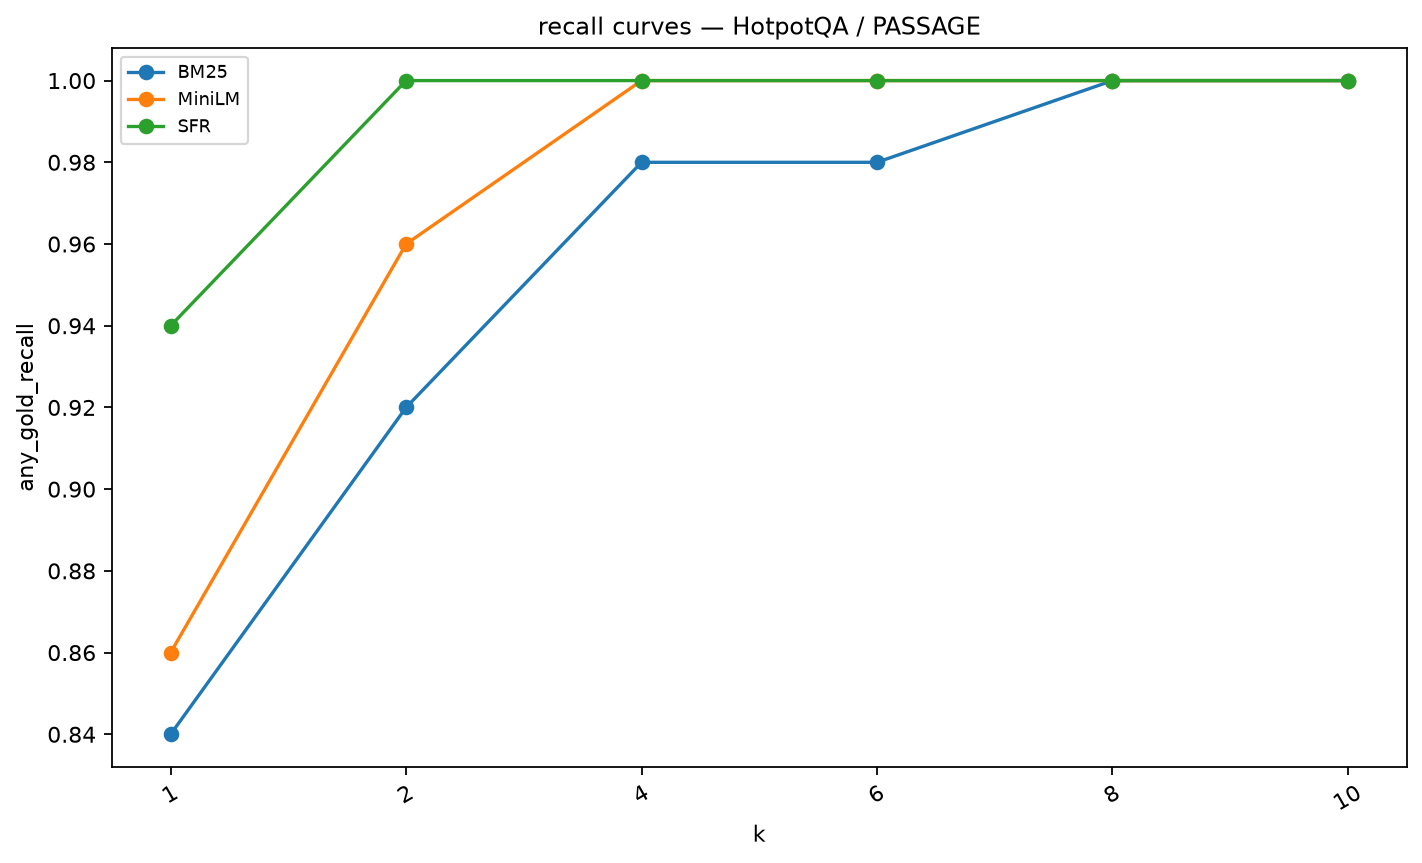

recall_curves HotpotQA / PROPOSITION


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,55db50b68b85b4157276,5ab2f53d5542991669774157,HotpotQA,PROPOSITION,NaN,23.956522,P0,5ab2f53d5542991669774157,BM25,False,1,0.0,...,1,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,NaN,17,0,['eb6fff3714b9e370189bc30f0e7d38eb'],0.000149,NaN,NaN,NaN,NaN
1,55db50b68b85b4157276,5ab2f53d5542991669774157,HotpotQA,PROPOSITION,NaN,23.956522,P0,5ab2f53d5542991669774157,BM25,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.130435,45,0,"['eb6fff3714b9e370189bc30f0e7d38eb', 'b56ecae423c7480151d01e69c512...",0.000149,NaN,NaN,NaN,NaN
2,55db50b68b85b4157276,5ab2f53d5542991669774157,HotpotQA,PROPOSITION,NaN,23.956522,P0,5ab2f53d5542991669774157,BM25,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.096231,101,0,"['eb6fff3714b9e370189bc30f0e7d38eb', 'b56ecae423c7480151d01e69c512...",0.000149,NaN,NaN,NaN,NaN
3,55db50b68b85b4157276,5ab2f53d5542991669774157,HotpotQA,PROPOSITION,NaN,23.956522,P0,5ab2f53d5542991669774157,BM25,False,6,0.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.109933,135,0,"['eb6fff3714b9e370189bc30f0e7d38eb', 'b56ecae423c7480151d01e69c512...",0.000149,NaN,NaN,NaN,NaN
4,55db50b68b85b4157276,5ab2f53d5542991669774157,HotpotQA,PROPOSITION,NaN,23.956522,P0,5ab2f53d5542991669774157,BM25,False,8,0.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.087096,224,0,"['eb6fff3714b9e370189bc30f0e7d38eb', 'b56ecae423c7480151d01e69c512...",0.000149,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,a5ccd1b17003da385cf5,5ac02c4a5542992a796decbd,HotpotQA,PROPOSITION,NaN,22.194805,P0,5ac02c4a5542992a796decbd,MiniLM,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,0.2,0.096774,52,0,"['736db368a7d97d186cf74a93dc3a9bcc', '03d2257e29c218c200bba6fdcb8e...",0.646452,0.608444,0.645445,0.007571,0.000109
896,a5ccd1b17003da385cf5,5ac02c4a5542992a796decbd,HotpotQA,PROPOSITION,NaN,22.194805,P0,5ac02c4a5542992a796decbd,MiniLM,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,0.2,0.041902,85,0,"['736db368a7d97d186cf74a93dc3a9bcc', '03d2257e29c218c200bba6fdcb8e...",0.646452,0.608444,0.645445,0.007571,0.000109
897,a5ccd1b17003da385cf5,5ac02c4a5542992a796decbd,HotpotQA,PROPOSITION,NaN,22.194805,P0,5ac02c4a5542992a796decbd,MiniLM,False,6,0.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,0.2,0.043622,136,0,"['736db368a7d97d186cf74a93dc3a9bcc', '03d2257e29c218c200bba6fdcb8e...",0.646452,0.608444,0.645445,0.007571,0.000109
898,a5ccd1b17003da385cf5,5ac02c4a5542992a796decbd,HotpotQA,PROPOSITION,NaN,22.194805,P0,5ac02c4a5542992a796decbd,MiniLM,False,8,0.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,0.2,0.056552,228,0,"['736db368a7d97d186cf74a93dc3a9bcc', '03d2257e29c218c200bba6fdcb8e...",0.646452,0.608444,0.645445,0.007571,0.000109


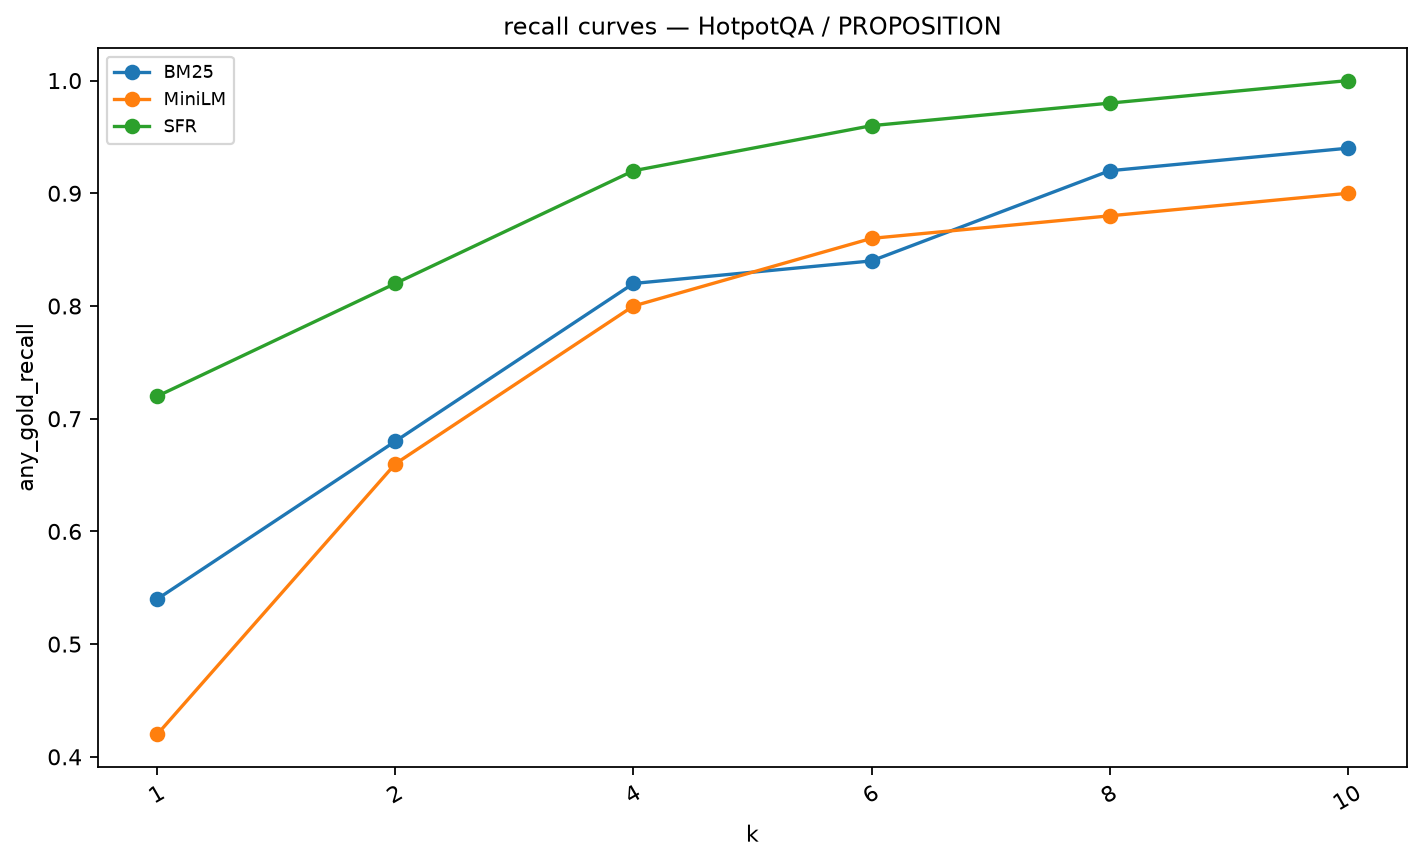

recall_curves HotpotQA / SENTENCE


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,1,0.0,...,1,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,NaN,34,0,['56c9ad5facead84a1c21492b36f7fcd2'],0.000284,NaN,NaN,NaN,NaN
1,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.121212,62,0,"['56c9ad5facead84a1c21492b36f7fcd2', 'c426f3b9aef0adad127ce9a0922a...",0.000284,NaN,NaN,NaN,NaN
2,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.107842,121,0,"['56c9ad5facead84a1c21492b36f7fcd2', 'c426f3b9aef0adad127ce9a0922a...",0.000284,NaN,NaN,NaN,NaN
3,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,6,0.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.113762,200,0,"['56c9ad5facead84a1c21492b36f7fcd2', 'c426f3b9aef0adad127ce9a0922a...",0.000284,NaN,NaN,NaN,NaN
4,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,8,0.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.127121,288,0,"['56c9ad5facead84a1c21492b36f7fcd2', 'c426f3b9aef0adad127ce9a0922a...",0.000284,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,69361abe8d8c0d1d61a8,5ae455d45542996836b02c7b,HotpotQA,SENTENCE,NaN,25.634615,P0,5ae455d45542996836b02c7b,SFR,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.111111,39,0,"['754b795c9f831cb7081cefb82da78314', '8d663650ce37ba82acb336fc3a41...",2.246543,2.061207,2.245838,0.041279,0.000082
896,69361abe8d8c0d1d61a8,5ae455d45542996836b02c7b,HotpotQA,SENTENCE,NaN,25.634615,P0,5ae455d45542996836b02c7b,SFR,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.084187,82,0,"['754b795c9f831cb7081cefb82da78314', '8d663650ce37ba82acb336fc3a41...",2.246543,2.061207,2.245838,0.041279,0.000082
897,69361abe8d8c0d1d61a8,5ae455d45542996836b02c7b,HotpotQA,SENTENCE,NaN,25.634615,P0,5ae455d45542996836b02c7b,SFR,False,6,1.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.078827,157,0,"['754b795c9f831cb7081cefb82da78314', '8d663650ce37ba82acb336fc3a41...",2.246543,2.061207,2.245838,0.041279,0.000082
898,69361abe8d8c0d1d61a8,5ae455d45542996836b02c7b,HotpotQA,SENTENCE,NaN,25.634615,P0,5ae455d45542996836b02c7b,SFR,False,8,1.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.066729,220,0,"['754b795c9f831cb7081cefb82da78314', '8d663650ce37ba82acb336fc3a41...",2.246543,2.061207,2.245838,0.041279,0.000082


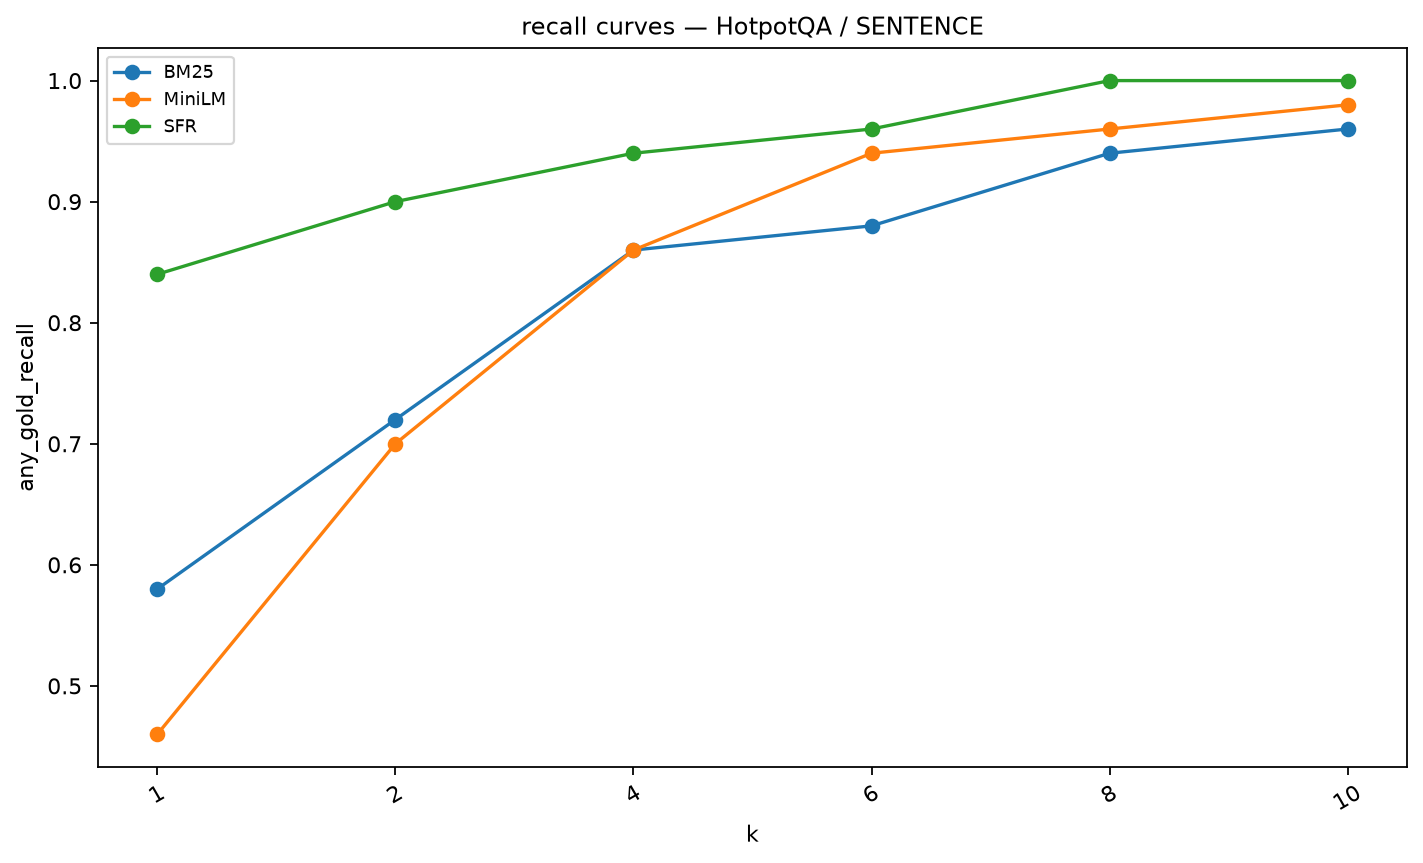

recall_curves QASPER / PASSAGE


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,0bc6111c85ee7f5f4a69,45,QASPER,PASSAGE,245.409091,245.409091,P0,155,MiniLM,False,1,0.0,...,1,Full non-whitespace annotated-character union coverage; repeated Q...,0.090909,NaN,256,0,['98b0317837656f910e37d34d37c1f1bb'],3.552184,0.466029,3.537660,0.010361,0.014325
1,0bc6111c85ee7f5f4a69,45,QASPER,PASSAGE,245.409091,245.409091,P0,155,MiniLM,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,0.090909,0.076923,512,0,"['98b0317837656f910e37d34d37c1f1bb', '56e73b57a1b2bdcc57d44e495efe...",3.552184,0.466029,3.537660,0.010361,0.014325
2,0bc6111c85ee7f5f4a69,45,QASPER,PASSAGE,245.409091,245.409091,P0,155,MiniLM,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,0.090909,0.116675,1021,0,"['98b0317837656f910e37d34d37c1f1bb', '56e73b57a1b2bdcc57d44e495efe...",3.552184,0.466029,3.537660,0.010361,0.014325
3,0bc6111c85ee7f5f4a69,45,QASPER,PASSAGE,245.409091,245.409091,P0,155,MiniLM,False,6,0.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,0.090909,0.137786,1533,0,"['98b0317837656f910e37d34d37c1f1bb', '56e73b57a1b2bdcc57d44e495efe...",3.552184,0.466029,3.537660,0.010361,0.014325
4,0bc6111c85ee7f5f4a69,45,QASPER,PASSAGE,245.409091,245.409091,P0,155,MiniLM,False,8,0.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,0.090909,0.131492,2045,0,"['98b0317837656f910e37d34d37c1f1bb', '56e73b57a1b2bdcc57d44e495efe...",3.552184,0.466029,3.537660,0.010361,0.014325
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,aacff50085079bad87b8,591,QASPER,PASSAGE,249.040000,249.040000,P0,1801,SFR,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,0.200000,0.113445,512,0,"['3dad317670696db1625b68889ea40a25', 'ef98d6d02b8de5601846202d284b...",2.786015,2.626962,2.740685,0.041312,0.044824
896,aacff50085079bad87b8,591,QASPER,PASSAGE,249.040000,249.040000,P0,1801,SFR,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,0.200000,0.131852,1024,0,"['3dad317670696db1625b68889ea40a25', 'ef98d6d02b8de5601846202d284b...",2.786015,2.626962,2.740685,0.041312,0.044824
897,aacff50085079bad87b8,591,QASPER,PASSAGE,249.040000,249.040000,P0,1801,SFR,False,6,1.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,0.200000,0.140102,1533,0,"['3dad317670696db1625b68889ea40a25', 'ef98d6d02b8de5601846202d284b...",2.786015,2.626962,2.740685,0.041312,0.044824
898,aacff50085079bad87b8,591,QASPER,PASSAGE,249.040000,249.040000,P0,1801,SFR,False,8,1.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,0.200000,0.134768,2045,0,"['3dad317670696db1625b68889ea40a25', 'ef98d6d02b8de5601846202d284b...",2.786015,2.626962,2.740685,0.041312,0.044824


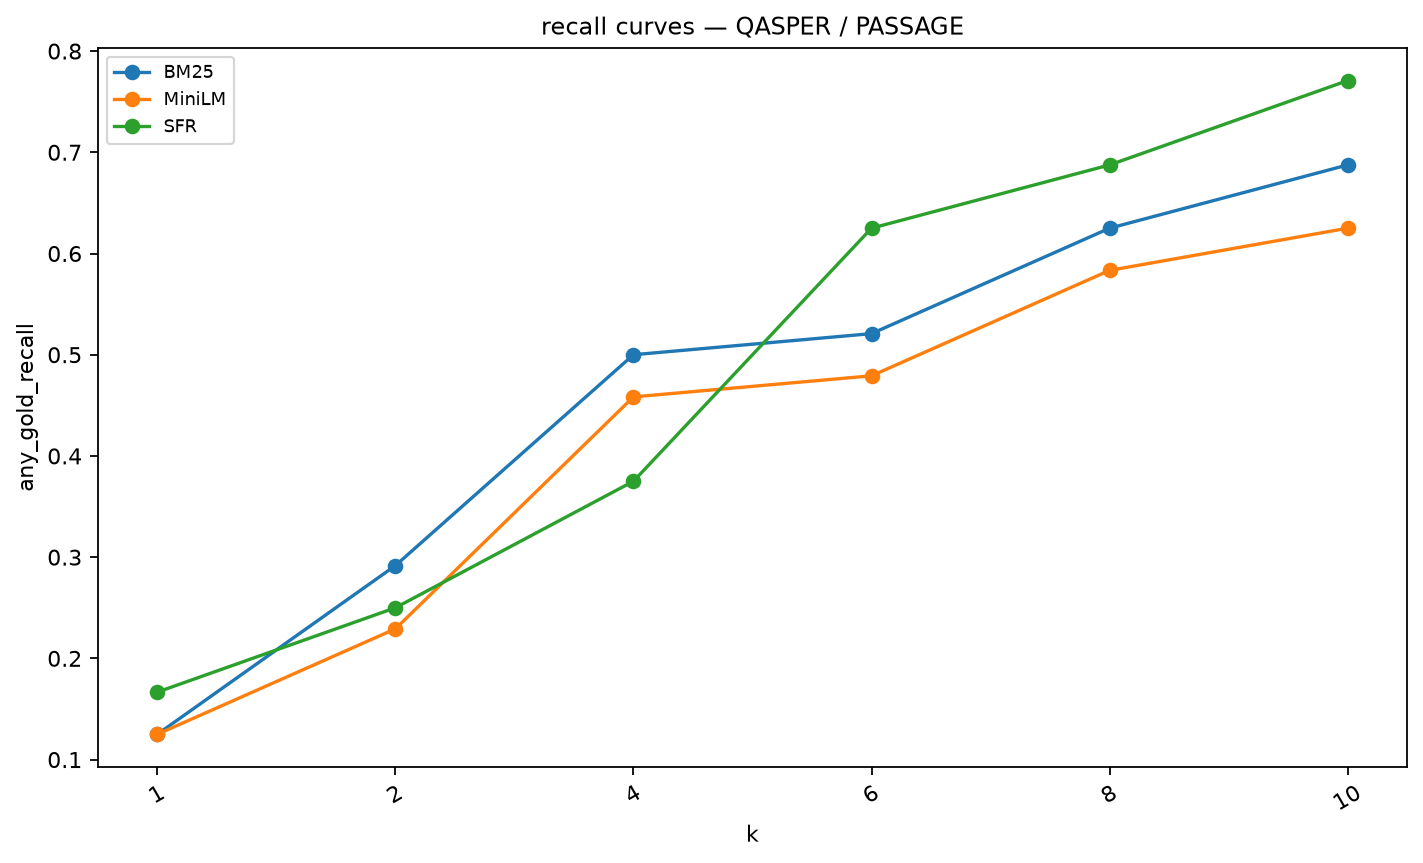

recall_curves QASPER / PROPOSITION


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,08eeaf51742df28d788e,591,QASPER,PROPOSITION,NaN,29.657143,P0,1801,SFR,False,1,0.0,...,1,Full non-whitespace annotated-character union coverage; repeated Q...,0.007463,NaN,7,0,['0c264317015608e2b5abcdf1b218294d'],1.415431,8.523570,1.413088,0.041312,0.000066
1,08eeaf51742df28d788e,591,QASPER,PROPOSITION,NaN,29.657143,P0,1801,SFR,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,0.007463,0.033333,48,0,"['0c264317015608e2b5abcdf1b218294d', 'c723314be6eeffec7a4b11637d1c...",1.415431,8.523570,1.413088,0.041312,0.000066
2,08eeaf51742df28d788e,591,QASPER,PROPOSITION,NaN,29.657143,P0,1801,SFR,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,0.007463,0.118831,210,0,"['0c264317015608e2b5abcdf1b218294d', 'c723314be6eeffec7a4b11637d1c...",1.415431,8.523570,1.413088,0.041312,0.000066
3,08eeaf51742df28d788e,591,QASPER,PROPOSITION,NaN,29.657143,P0,1801,SFR,False,6,0.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,0.007463,0.095570,286,0,"['0c264317015608e2b5abcdf1b218294d', 'c723314be6eeffec7a4b11637d1c...",1.415431,8.523570,1.413088,0.041312,0.000066
4,08eeaf51742df28d788e,591,QASPER,PROPOSITION,NaN,29.657143,P0,1801,SFR,False,8,0.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,0.007463,0.094166,381,0,"['0c264317015608e2b5abcdf1b218294d', 'c723314be6eeffec7a4b11637d1c...",1.415431,8.523570,1.413088,0.041312,0.000066
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,a5ccd1b17003da385cf5,665,QASPER,PROPOSITION,NaN,26.750000,P0,1964,MiniLM,False,2,NaN,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.133333,51,0,"['ed4eb3ad09f47a925f56582110bc3ba3', 'b78b940895aab83eb78d127d6c5e...",0.005651,0.983131,0.005141,0.006866,0.000057
896,a5ccd1b17003da385cf5,665,QASPER,PROPOSITION,NaN,26.750000,P0,1964,MiniLM,False,4,NaN,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.120522,97,0,"['ed4eb3ad09f47a925f56582110bc3ba3', 'b78b940895aab83eb78d127d6c5e...",0.005651,0.983131,0.005141,0.006866,0.000057
897,a5ccd1b17003da385cf5,665,QASPER,PROPOSITION,NaN,26.750000,P0,1964,MiniLM,False,6,NaN,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.145735,166,0,"['ed4eb3ad09f47a925f56582110bc3ba3', 'b78b940895aab83eb78d127d6c5e...",0.005651,0.983131,0.005141,0.006866,0.000057
898,a5ccd1b17003da385cf5,665,QASPER,PROPOSITION,NaN,26.750000,P0,1964,MiniLM,False,8,NaN,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.114656,232,0,"['ed4eb3ad09f47a925f56582110bc3ba3', 'b78b940895aab83eb78d127d6c5e...",0.005651,0.983131,0.005141,0.006866,0.000057


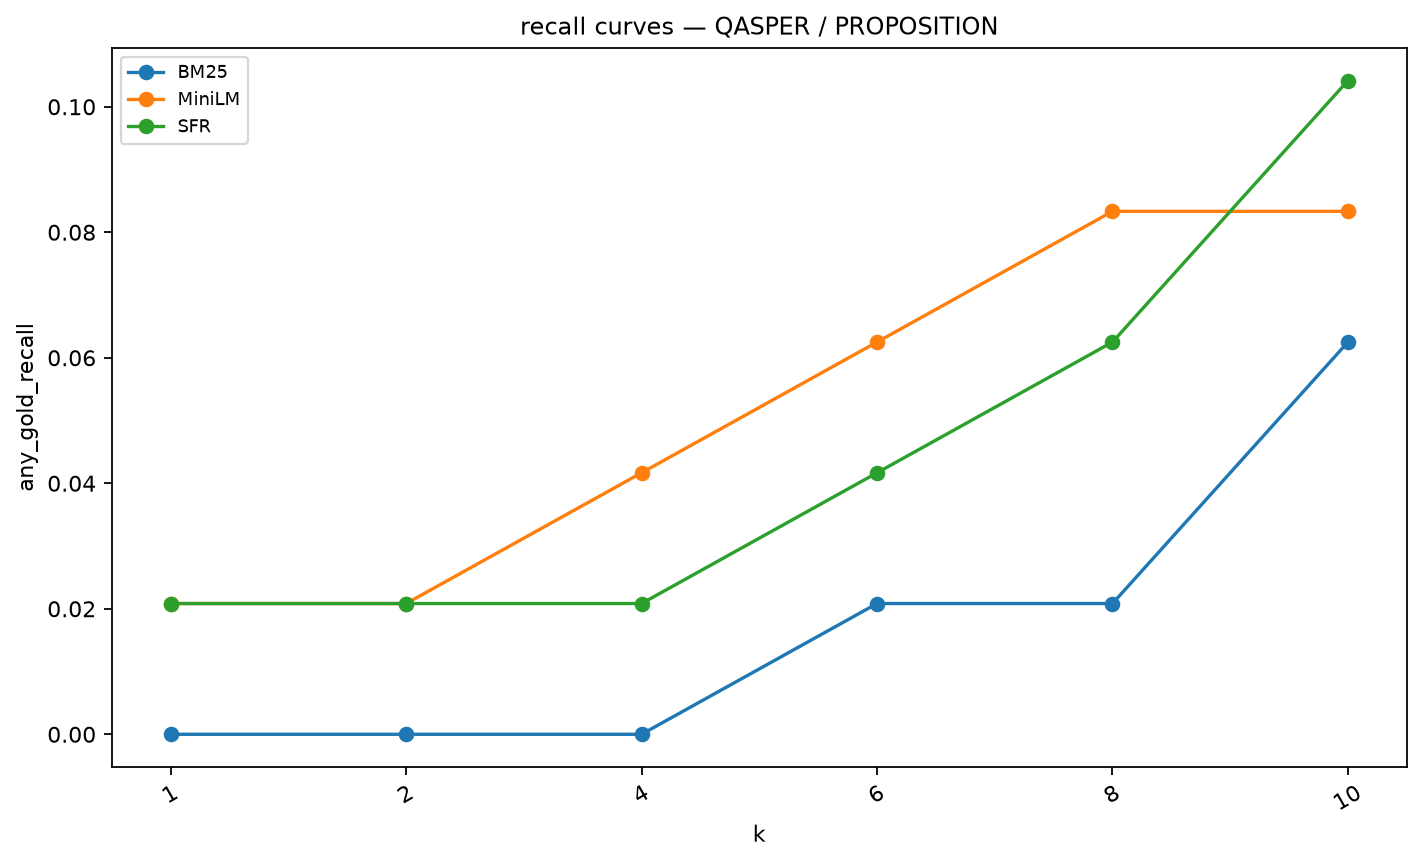

recall_curves QASPER / SENTENCE


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,43db754dc48ca3463c07,467,QASPER,SENTENCE,NaN,24.875,P0,1496,MiniLM,False,1,0.0,...,1,Full non-whitespace annotated-character union coverage; repeated Q...,0.0,NaN,16,1,['bf0e9bede56681f47a7b4a8eeb4a1e6d'],0.002170,0.341079,0.001929,0.008893,0.000047
1,43db754dc48ca3463c07,467,QASPER,SENTENCE,NaN,24.875,P0,1496,MiniLM,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,0.0,0.117647,27,1,"['bf0e9bede56681f47a7b4a8eeb4a1e6d', '56baf71adc50a73b951f8fae5d3b...",0.002170,0.341079,0.001929,0.008893,0.000047
2,43db754dc48ca3463c07,467,QASPER,SENTENCE,NaN,24.875,P0,1496,MiniLM,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,0.0,0.067066,77,1,"['bf0e9bede56681f47a7b4a8eeb4a1e6d', '56baf71adc50a73b951f8fae5d3b...",0.002170,0.341079,0.001929,0.008893,0.000047
3,43db754dc48ca3463c07,467,QASPER,SENTENCE,NaN,24.875,P0,1496,MiniLM,False,6,0.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,0.0,0.056053,157,1,"['bf0e9bede56681f47a7b4a8eeb4a1e6d', '56baf71adc50a73b951f8fae5d3b...",0.002170,0.341079,0.001929,0.008893,0.000047
4,43db754dc48ca3463c07,467,QASPER,SENTENCE,NaN,24.875,P0,1496,MiniLM,False,8,0.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,0.0,0.057216,230,1,"['bf0e9bede56681f47a7b4a8eeb4a1e6d', '56baf71adc50a73b951f8fae5d3b...",0.002170,0.341079,0.001929,0.008893,0.000047
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,bd4f9f7b6db5f1cc0603,735,QASPER,SENTENCE,NaN,34.812,P0,2102,BM25,False,2,0.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,0.0,0.084746,107,2,"['f8211b702a114f8df84825bbac6d86ec', '170c630a6bf2cba5f9333d80425c...",0.000646,NaN,NaN,NaN,NaN
896,bd4f9f7b6db5f1cc0603,735,QASPER,SENTENCE,NaN,34.812,P0,2102,BM25,False,4,0.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,0.0,0.097860,161,2,"['f8211b702a114f8df84825bbac6d86ec', '170c630a6bf2cba5f9333d80425c...",0.000646,NaN,NaN,NaN,NaN
897,bd4f9f7b6db5f1cc0603,735,QASPER,SENTENCE,NaN,34.812,P0,2102,BM25,False,6,0.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,0.0,0.073764,261,2,"['f8211b702a114f8df84825bbac6d86ec', '170c630a6bf2cba5f9333d80425c...",0.000646,NaN,NaN,NaN,NaN
898,bd4f9f7b6db5f1cc0603,735,QASPER,SENTENCE,NaN,34.812,P0,2102,BM25,False,8,0.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,0.0,0.091308,302,2,"['f8211b702a114f8df84825bbac6d86ec', '170c630a6bf2cba5f9333d80425c...",0.000646,NaN,NaN,NaN,NaN


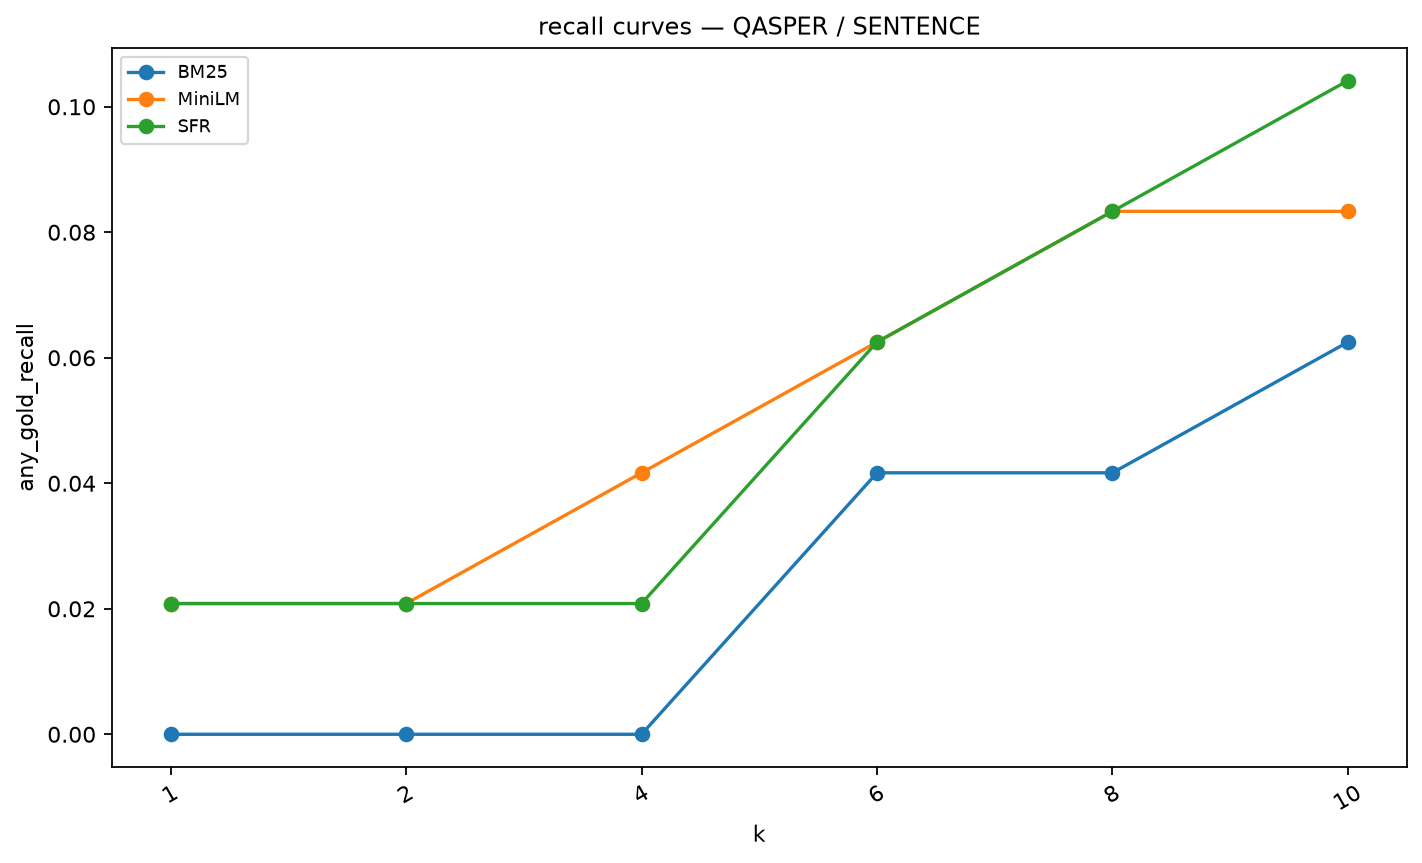

recall_curves SciFact / PASSAGE


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,0bc6111c85ee7f5f4a69,312,SciFact,PASSAGE,330.294231,330.294231,P0,312,MiniLM,False,1,NaN,...,1,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,NaN,265,0,['ab8308428a5c066294c16615563fd61d'],0.210245,114.823021,0.170868,0.008024,0.012646
1,0bc6111c85ee7f5f4a69,312,SciFact,PASSAGE,330.294231,330.294231,P0,312,MiniLM,False,2,NaN,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.109705,572,0,"['ab8308428a5c066294c16615563fd61d', '8dcc25b3b09b31548a8f013a0126...",0.210245,114.823021,0.170868,0.008024,0.012646
2,0bc6111c85ee7f5f4a69,312,SciFact,PASSAGE,330.294231,330.294231,P0,312,MiniLM,False,4,NaN,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.118250,1046,0,"['ab8308428a5c066294c16615563fd61d', '8dcc25b3b09b31548a8f013a0126...",0.210245,114.823021,0.170868,0.008024,0.012646
3,0bc6111c85ee7f5f4a69,312,SciFact,PASSAGE,330.294231,330.294231,P0,312,MiniLM,False,6,NaN,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.108471,1701,0,"['ab8308428a5c066294c16615563fd61d', '8dcc25b3b09b31548a8f013a0126...",0.210245,114.823021,0.170868,0.008024,0.012646
4,0bc6111c85ee7f5f4a69,312,SciFact,PASSAGE,330.294231,330.294231,P0,312,MiniLM,False,8,NaN,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.101229,2202,0,"['ab8308428a5c066294c16615563fd61d', '8dcc25b3b09b31548a8f013a0126...",0.210245,114.823021,0.170868,0.008024,0.012646
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,0bc6111c85ee7f5f4a69,960,SciFact,PASSAGE,330.294231,330.294231,P0,960,MiniLM,False,2,1.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.083650,692,0,"['d57de4c21f533ac80318cb611236675a', 'f8697aa11ee394201ce0deb3017f...",0.210840,114.823021,0.171030,0.010652,0.014277
896,0bc6111c85ee7f5f4a69,960,SciFact,PASSAGE,330.294231,330.294231,P0,960,MiniLM,False,4,1.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.083402,1424,0,"['d57de4c21f533ac80318cb611236675a', 'f8697aa11ee394201ce0deb3017f...",0.210840,114.823021,0.171030,0.010652,0.014277
897,0bc6111c85ee7f5f4a69,960,SciFact,PASSAGE,330.294231,330.294231,P0,960,MiniLM,False,6,1.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.085711,2272,0,"['d57de4c21f533ac80318cb611236675a', 'f8697aa11ee394201ce0deb3017f...",0.210840,114.823021,0.171030,0.010652,0.014277
898,0bc6111c85ee7f5f4a69,960,SciFact,PASSAGE,330.294231,330.294231,P0,960,MiniLM,False,8,1.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.082663,3059,0,"['d57de4c21f533ac80318cb611236675a', 'f8697aa11ee394201ce0deb3017f...",0.210840,114.823021,0.171030,0.010652,0.014277


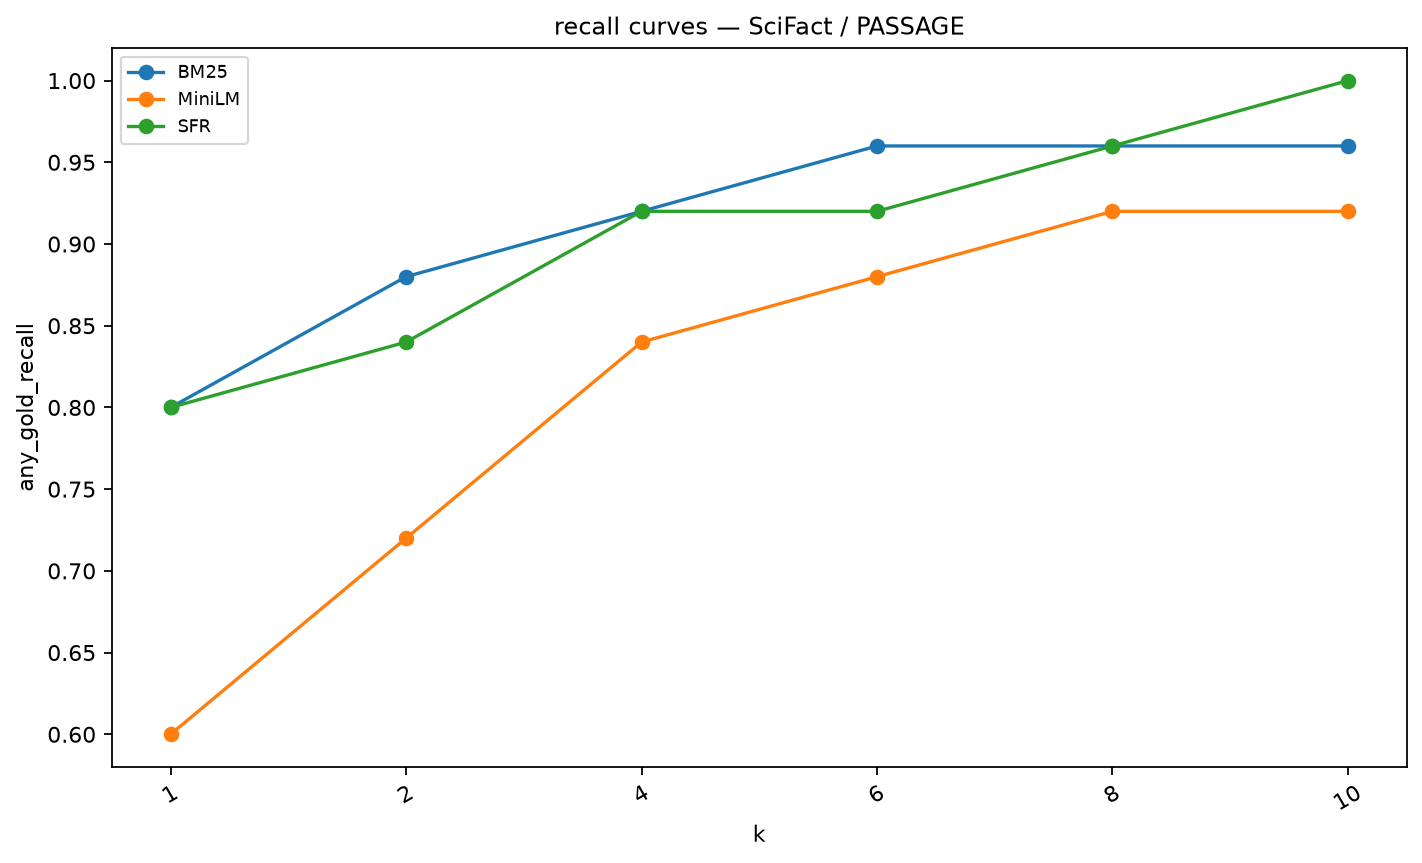

recall_curves SciFact / PROPOSITION


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,a5ccd1b17003da385cf5,384,SciFact,PROPOSITION,NaN,32.031467,P0,384,MiniLM,False,1,NaN,...,1,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,NaN,30,0,['f98d17432a61623d4af8d34f4dc5f11b'],1.572836,394.256102,1.274801,0.012649,0.001096
1,a5ccd1b17003da385cf5,384,SciFact,PROPOSITION,NaN,32.031467,P0,384,MiniLM,False,2,NaN,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.052632,56,0,"['f98d17432a61623d4af8d34f4dc5f11b', 'b6a0f2d3c8c00de83ad053bcd768...",1.572836,394.256102,1.274801,0.012649,0.001096
2,a5ccd1b17003da385cf5,384,SciFact,PROPOSITION,NaN,32.031467,P0,384,MiniLM,False,4,NaN,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.102698,125,0,"['f98d17432a61623d4af8d34f4dc5f11b', 'b6a0f2d3c8c00de83ad053bcd768...",1.572836,394.256102,1.274801,0.012649,0.001096
3,a5ccd1b17003da385cf5,384,SciFact,PROPOSITION,NaN,32.031467,P0,384,MiniLM,False,6,NaN,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.085023,193,0,"['f98d17432a61623d4af8d34f4dc5f11b', 'b6a0f2d3c8c00de83ad053bcd768...",1.572836,394.256102,1.274801,0.012649,0.001096
4,a5ccd1b17003da385cf5,384,SciFact,PROPOSITION,NaN,32.031467,P0,384,MiniLM,False,8,NaN,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.065473,250,0,"['f98d17432a61623d4af8d34f4dc5f11b', 'b6a0f2d3c8c00de83ad053bcd768...",1.572836,394.256102,1.274801,0.012649,0.001096
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,08eeaf51742df28d788e,1024,SciFact,PROPOSITION,NaN,32.031467,P0,1024,SFR,False,2,1.0,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.140000,94,0,"['1a9904a3f0018d691c0feb28f8731bee', '05e95ced35d0ad8a3d15aa39e1cc...",2.538886,2194.186446,1.820589,0.057639,0.001527
896,08eeaf51742df28d788e,1024,SciFact,PROPOSITION,NaN,32.031467,P0,1024,SFR,False,4,1.0,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.115698,241,0,"['1a9904a3f0018d691c0feb28f8731bee', '05e95ced35d0ad8a3d15aa39e1cc...",2.538886,2194.186446,1.820589,0.057639,0.001527
897,08eeaf51742df28d788e,1024,SciFact,PROPOSITION,NaN,32.031467,P0,1024,SFR,False,6,1.0,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.098657,311,0,"['1a9904a3f0018d691c0feb28f8731bee', '05e95ced35d0ad8a3d15aa39e1cc...",2.538886,2194.186446,1.820589,0.057639,0.001527
898,08eeaf51742df28d788e,1024,SciFact,PROPOSITION,NaN,32.031467,P0,1024,SFR,False,8,1.0,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.101105,404,0,"['1a9904a3f0018d691c0feb28f8731bee', '05e95ced35d0ad8a3d15aa39e1cc...",2.538886,2194.186446,1.820589,0.057639,0.001527


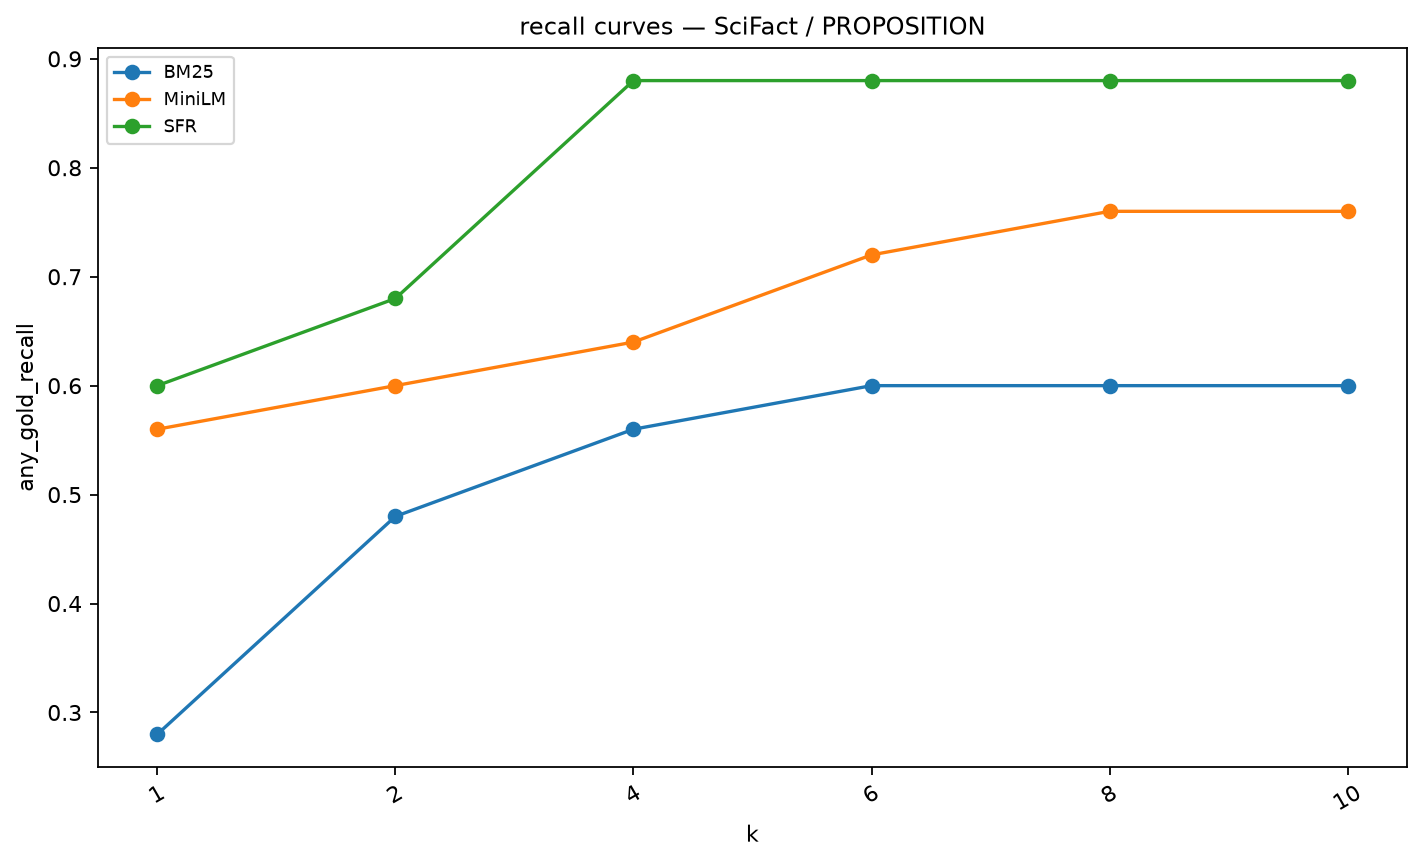

recall_curves SciFact / SENTENCE


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,69361abe8d8c0d1d61a8,575,SciFact,SENTENCE,NaN,33.421023,P0,575,SFR,False,1,NaN,...,1,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,NaN,23,0,['760a54854faf701592022594bfd3e200'],2.490596,2118.681556,1.787017,0.058499,0.001382
1,69361abe8d8c0d1d61a8,575,SciFact,SENTENCE,NaN,33.421023,P0,575,SFR,False,2,NaN,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.214286,55,0,"['760a54854faf701592022594bfd3e200', 'e86c96003e5b73a58f01ae8c3ee1...",2.490596,2118.681556,1.787017,0.058499,0.001382
2,69361abe8d8c0d1d61a8,575,SciFact,SENTENCE,NaN,33.421023,P0,575,SFR,False,4,NaN,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.078459,138,0,"['760a54854faf701592022594bfd3e200', 'e86c96003e5b73a58f01ae8c3ee1...",2.490596,2118.681556,1.787017,0.058499,0.001382
3,69361abe8d8c0d1d61a8,575,SciFact,SENTENCE,NaN,33.421023,P0,575,SFR,False,6,NaN,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.085973,247,0,"['760a54854faf701592022594bfd3e200', 'e86c96003e5b73a58f01ae8c3ee1...",2.490596,2118.681556,1.787017,0.058499,0.001382
4,69361abe8d8c0d1d61a8,575,SciFact,SENTENCE,NaN,33.421023,P0,575,SFR,False,8,NaN,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.078711,315,0,"['760a54854faf701592022594bfd3e200', 'e86c96003e5b73a58f01ae8c3ee1...",2.490596,2118.681556,1.787017,0.058499,0.001382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,69361abe8d8c0d1d61a8,544,SciFact,SENTENCE,NaN,33.421023,P0,544,SFR,False,2,NaN,...,2,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.086957,97,0,"['9a87faafcbe97c0dc49d8ed2ac4a8339', '1428bc63b75c7957470e574a95f8...",2.487707,2118.681556,1.771873,0.057921,0.001388
896,69361abe8d8c0d1d61a8,544,SciFact,SENTENCE,NaN,33.421023,P0,544,SFR,False,4,NaN,...,4,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.068812,193,0,"['9a87faafcbe97c0dc49d8ed2ac4a8339', '1428bc63b75c7957470e574a95f8...",2.487707,2118.681556,1.771873,0.057921,0.001388
897,69361abe8d8c0d1d61a8,544,SciFact,SENTENCE,NaN,33.421023,P0,544,SFR,False,6,NaN,...,6,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.083434,266,0,"['9a87faafcbe97c0dc49d8ed2ac4a8339', '1428bc63b75c7957470e574a95f8...",2.487707,2118.681556,1.771873,0.057921,0.001388
898,69361abe8d8c0d1d61a8,544,SciFact,SENTENCE,NaN,33.421023,P0,544,SFR,False,8,NaN,...,8,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.077652,357,0,"['9a87faafcbe97c0dc49d8ed2ac4a8339', '1428bc63b75c7957470e574a95f8...",2.487707,2118.681556,1.771873,0.057921,0.001388


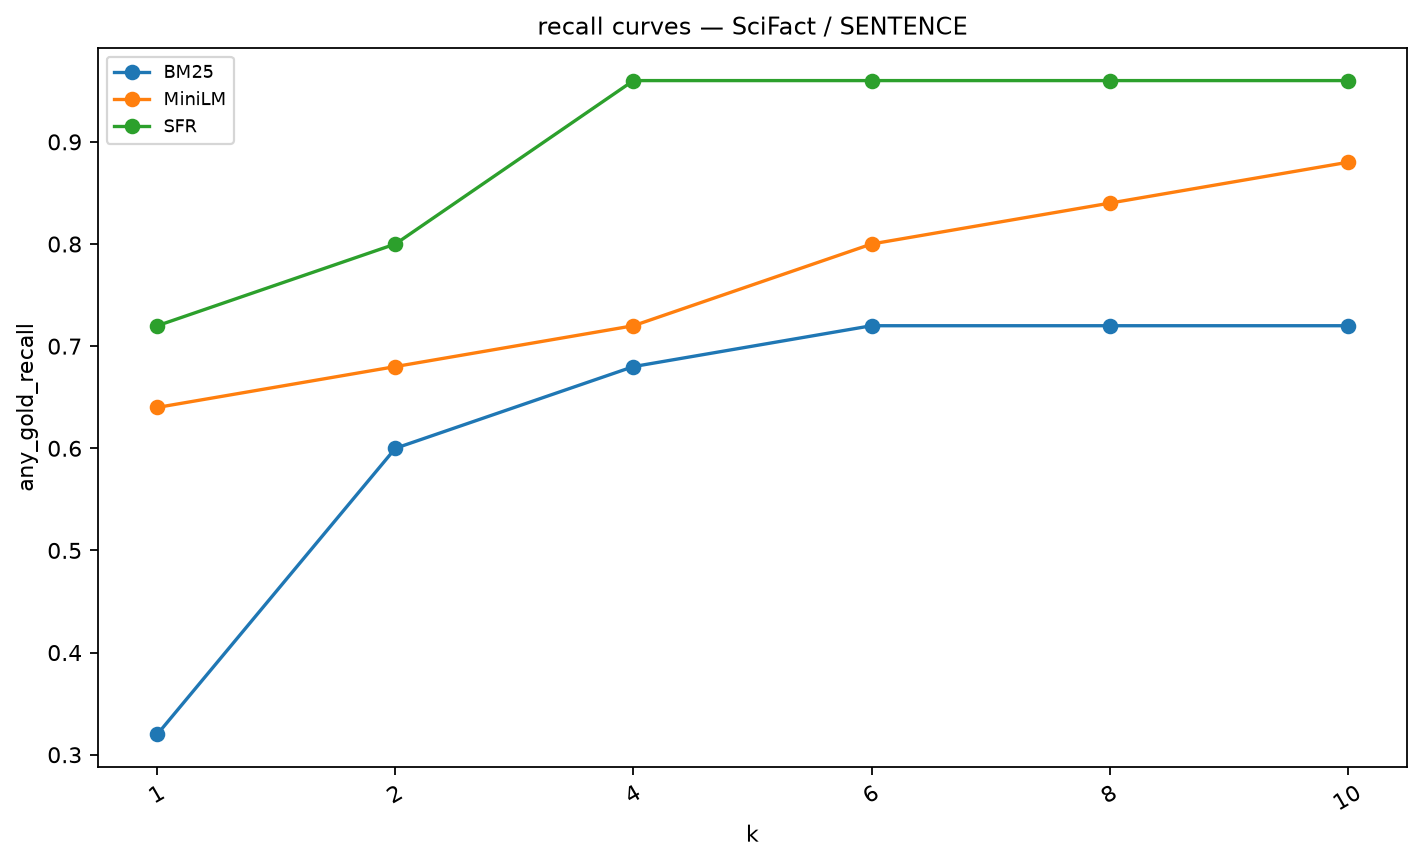

any_gold HotpotQA


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,25.025793,1.0,0.00,0.72,NaN,...,2.66,0.811524,NaN,30.16,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
1,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,25.025793,2.0,0.12,0.82,0.883061,...,2.66,0.811524,0.116939,64.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
2,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,25.025793,4.0,0.36,0.92,0.888660,...,2.66,0.811524,0.111340,123.36,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
3,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,25.025793,6.0,0.52,0.96,0.903035,...,2.66,0.811524,0.096965,182.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
4,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,25.025793,8.0,0.62,0.98,0.904230,...,2.66,0.811524,0.095770,244.04,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
5,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,25.025793,10.0,0.68,1.00,0.909971,...,2.66,0.811524,0.090029,302.30,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
6,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,135.104,135.104000,1.0,0.00,0.86,NaN,...,2.66,0.921667,NaN,92.20,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
7,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,135.104,135.104000,2.0,0.36,0.96,0.866448,...,2.66,0.921667,0.133552,209.84,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
8,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,135.104,135.104000,4.0,0.66,1.00,0.882296,...,2.66,0.921667,0.117704,488.96,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
9,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,135.104,135.104000,6.0,0.80,1.00,0.884688,...,2.66,0.921667,0.115312,761.72,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50


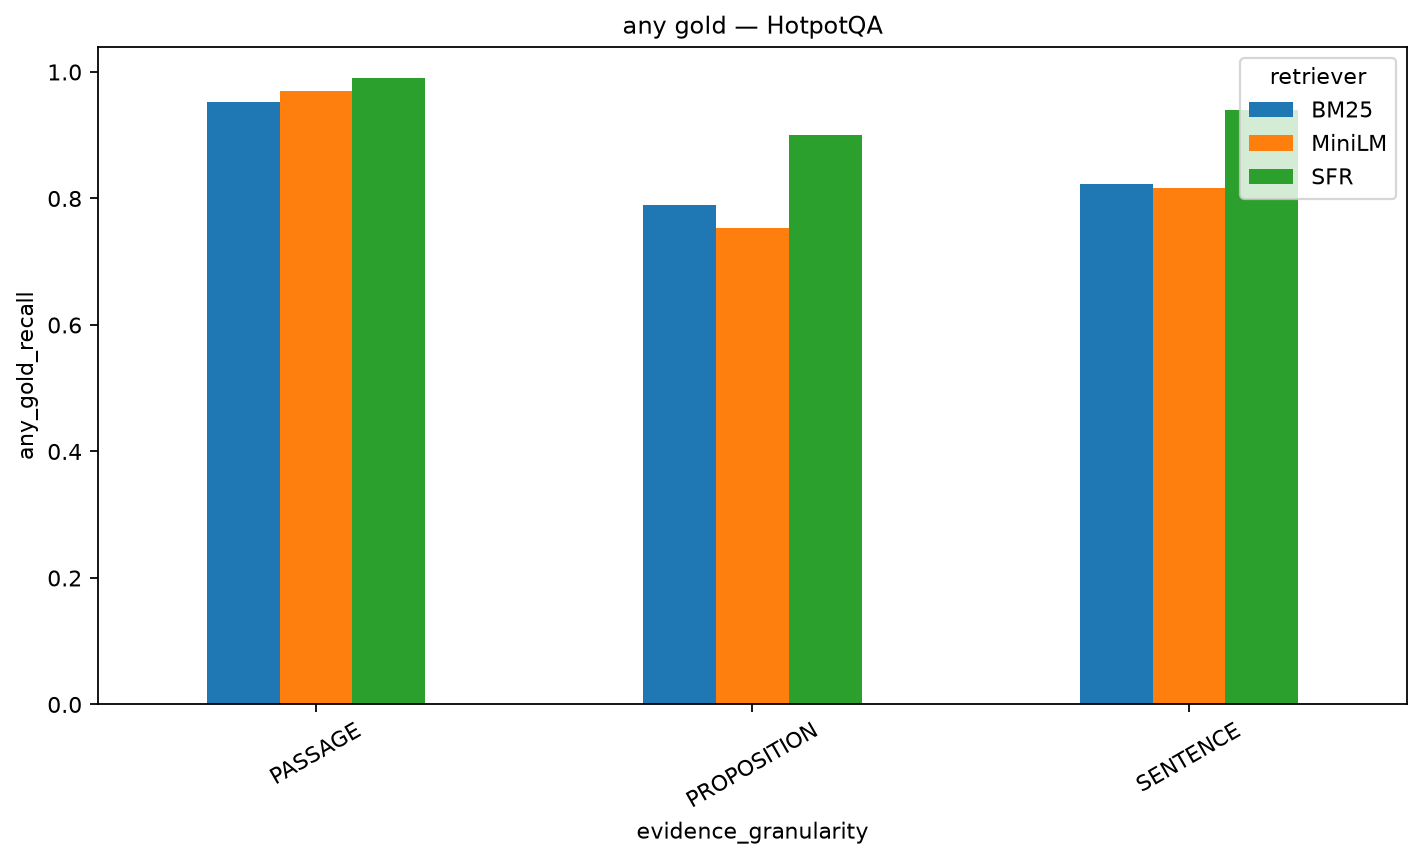

any_gold QASPER


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,26.772315,1.00,0.000000,0.020833,NaN,...,1.56,0.044608,NaN,31.40,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
1,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,26.772315,2.00,0.000000,0.020833,0.879444,...,1.56,0.044608,0.120556,65.32,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
2,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,26.772315,4.00,0.000000,0.020833,0.887691,...,1.56,0.044608,0.112309,135.24,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
3,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,26.772315,6.00,0.000000,0.041667,0.898436,...,1.56,0.044608,0.101564,205.74,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
4,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,26.772315,8.00,0.000000,0.062500,0.900940,...,1.56,0.044608,0.099060,280.88,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
5,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,26.772315,10.00,0.000000,0.104167,0.905111,...,1.56,0.044608,0.094889,353.46,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
6,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,247.824398,247.824398,1.00,0.062500,0.125000,NaN,...,1.56,0.285101,NaN,249.36,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
7,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,247.824398,247.824398,2.00,0.125000,0.229167,0.856868,...,1.56,0.285101,0.143132,503.40,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
8,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,247.824398,247.824398,4.00,0.333333,0.458333,0.859456,...,1.56,0.285101,0.140544,1009.24,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
9,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,247.824398,247.824398,5.92,0.416667,0.479167,0.863586,...,1.56,0.285101,0.136414,1474.22,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48


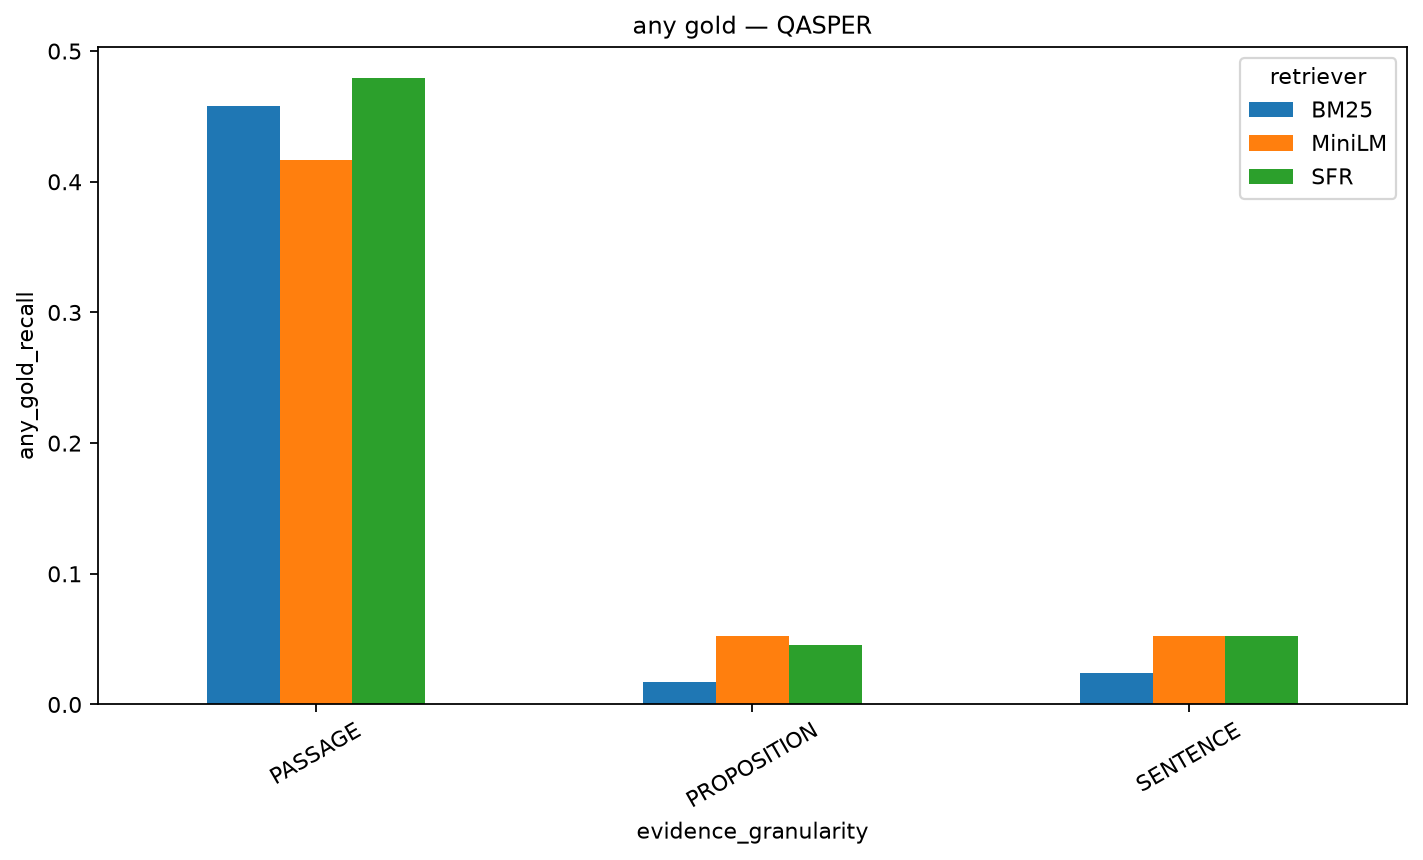

any_gold SciFact


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,32.031467,1.0,0.32,0.60,NaN,...,0.8,0.697743,NaN,43.68,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
1,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,32.031467,2.0,0.40,0.68,0.881924,...,0.8,0.697743,0.118076,85.36,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
2,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,32.031467,4.0,0.60,0.88,0.897499,...,0.8,0.697743,0.102501,167.28,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
3,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,32.031467,6.0,0.68,0.88,0.908069,...,0.8,0.697743,0.091931,250.94,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
4,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,32.031467,8.0,0.68,0.88,0.915191,...,0.8,0.697743,0.084809,345.92,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
5,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,32.031467,10.0,0.68,0.88,0.916999,...,0.8,0.697743,0.083001,430.74,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
6,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,330.294231,330.294231,1.0,0.60,0.60,NaN,...,0.8,0.710200,NaN,325.02,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
7,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,330.294231,330.294231,2.0,0.72,0.72,0.903110,...,0.8,0.710200,0.096890,635.66,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
8,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,330.294231,330.294231,4.0,0.84,0.84,0.904100,...,0.8,0.710200,0.095900,1292.76,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
9,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,330.294231,330.294231,6.0,0.88,0.88,0.906847,...,0.8,0.710200,0.093153,1965.28,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25


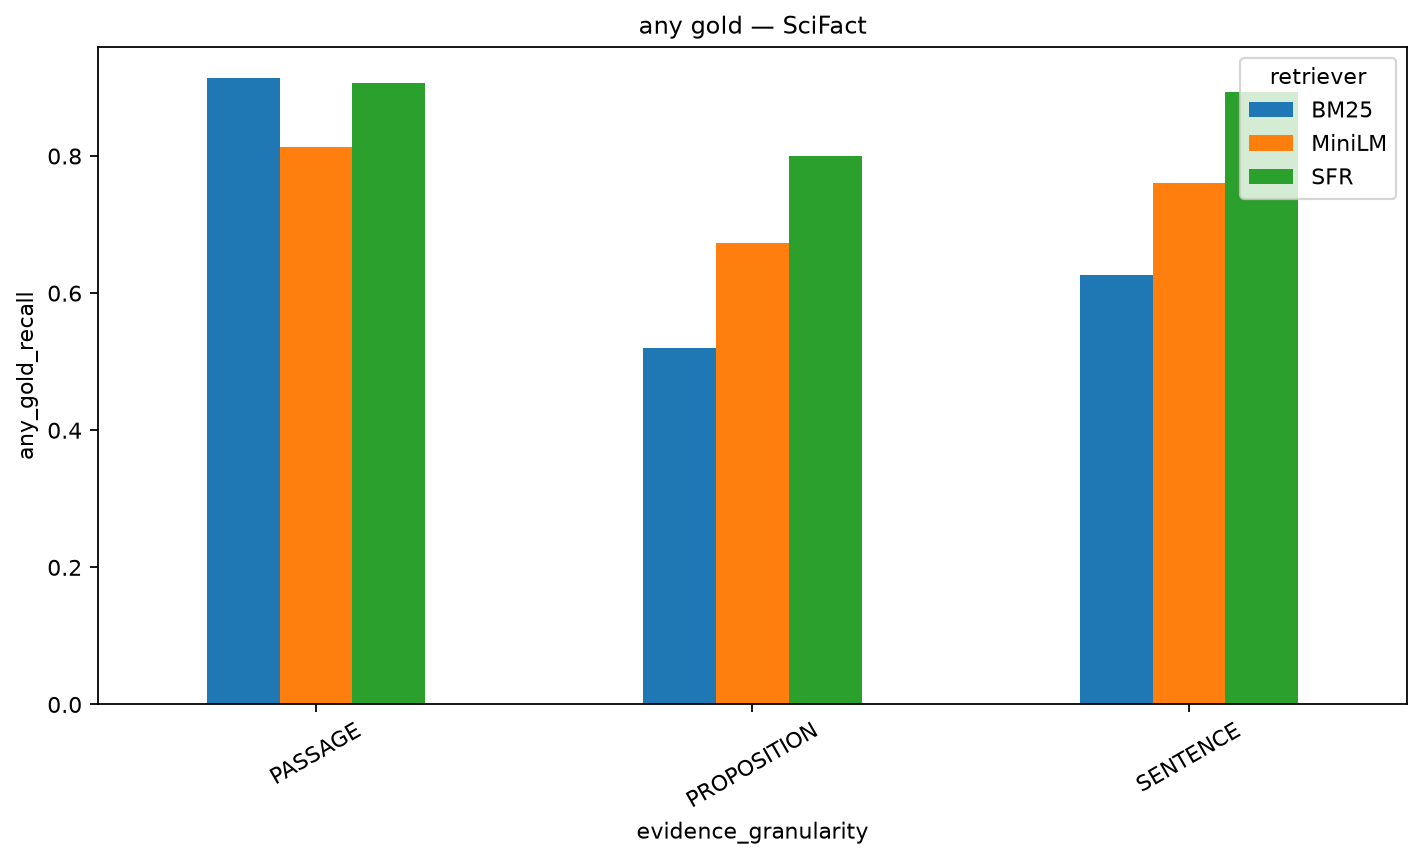

coverage_tokens HotpotQA


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,25.025793,1.0,0.00,0.72,NaN,...,2.66,0.811524,NaN,30.16,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
1,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,25.025793,2.0,0.12,0.82,0.883061,...,2.66,0.811524,0.116939,64.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
2,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,25.025793,4.0,0.36,0.92,0.888660,...,2.66,0.811524,0.111340,123.36,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
3,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,25.025793,6.0,0.52,0.96,0.903035,...,2.66,0.811524,0.096965,182.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
4,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,25.025793,8.0,0.62,0.98,0.904230,...,2.66,0.811524,0.095770,244.04,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
5,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,25.025793,10.0,0.68,1.00,0.909971,...,2.66,0.811524,0.090029,302.30,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
6,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,135.104,135.104000,1.0,0.00,0.86,NaN,...,2.66,0.921667,NaN,92.20,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
7,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,135.104,135.104000,2.0,0.36,0.96,0.866448,...,2.66,0.921667,0.133552,209.84,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
8,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,135.104,135.104000,4.0,0.66,1.00,0.882296,...,2.66,0.921667,0.117704,488.96,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
9,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,135.104,135.104000,6.0,0.80,1.00,0.884688,...,2.66,0.921667,0.115312,761.72,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50


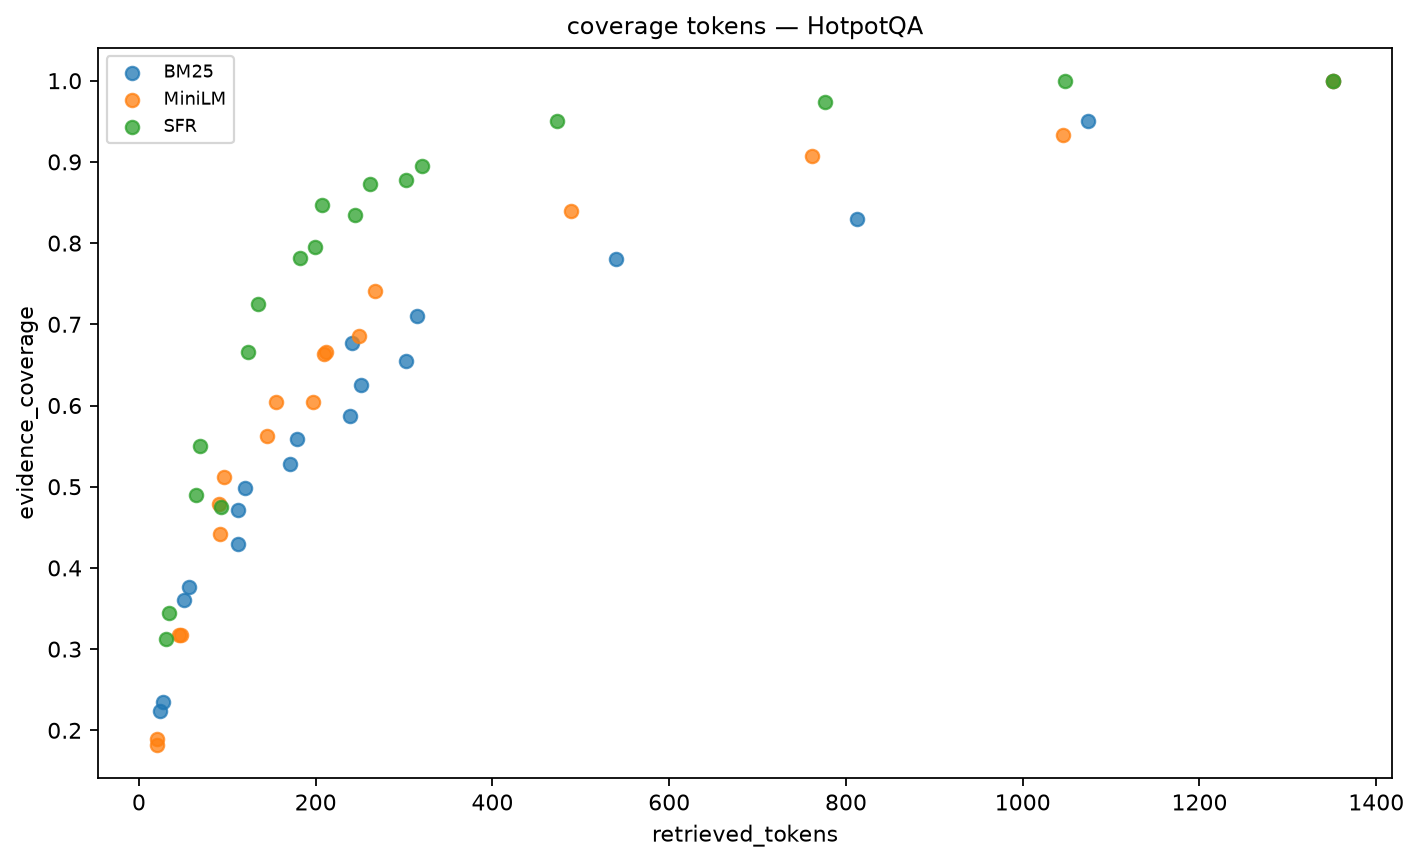

coverage_tokens QASPER


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,26.772315,1.00,0.000000,0.020833,NaN,...,1.56,0.044608,NaN,31.40,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
1,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,26.772315,2.00,0.000000,0.020833,0.879444,...,1.56,0.044608,0.120556,65.32,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
2,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,26.772315,4.00,0.000000,0.020833,0.887691,...,1.56,0.044608,0.112309,135.24,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
3,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,26.772315,6.00,0.000000,0.041667,0.898436,...,1.56,0.044608,0.101564,205.74,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
4,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,26.772315,8.00,0.000000,0.062500,0.900940,...,1.56,0.044608,0.099060,280.88,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
5,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,26.772315,10.00,0.000000,0.104167,0.905111,...,1.56,0.044608,0.094889,353.46,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
6,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,247.824398,247.824398,1.00,0.062500,0.125000,NaN,...,1.56,0.285101,NaN,249.36,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
7,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,247.824398,247.824398,2.00,0.125000,0.229167,0.856868,...,1.56,0.285101,0.143132,503.40,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
8,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,247.824398,247.824398,4.00,0.333333,0.458333,0.859456,...,1.56,0.285101,0.140544,1009.24,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
9,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,247.824398,247.824398,5.92,0.416667,0.479167,0.863586,...,1.56,0.285101,0.136414,1474.22,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48


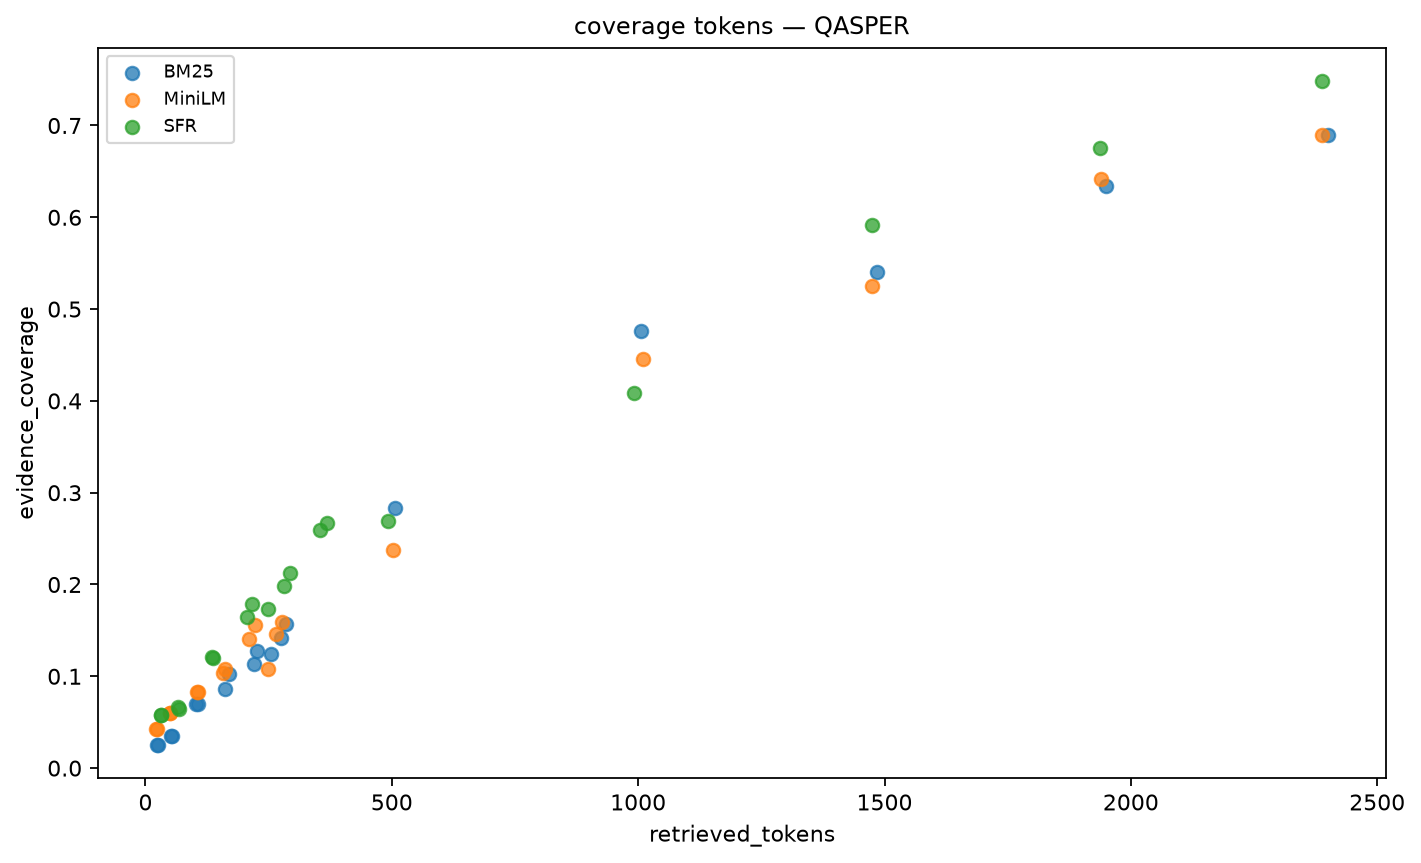

coverage_tokens SciFact


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,32.031467,1.0,0.32,0.60,NaN,...,0.8,0.697743,NaN,43.68,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
1,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,32.031467,2.0,0.40,0.68,0.881924,...,0.8,0.697743,0.118076,85.36,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
2,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,32.031467,4.0,0.60,0.88,0.897499,...,0.8,0.697743,0.102501,167.28,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
3,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,32.031467,6.0,0.68,0.88,0.908069,...,0.8,0.697743,0.091931,250.94,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
4,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,32.031467,8.0,0.68,0.88,0.915191,...,0.8,0.697743,0.084809,345.92,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
5,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,32.031467,10.0,0.68,0.88,0.916999,...,0.8,0.697743,0.083001,430.74,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
6,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,330.294231,330.294231,1.0,0.60,0.60,NaN,...,0.8,0.710200,NaN,325.02,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
7,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,330.294231,330.294231,2.0,0.72,0.72,0.903110,...,0.8,0.710200,0.096890,635.66,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
8,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,330.294231,330.294231,4.0,0.84,0.84,0.904100,...,0.8,0.710200,0.095900,1292.76,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
9,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,330.294231,330.294231,6.0,0.88,0.88,0.906847,...,0.8,0.710200,0.093153,1965.28,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25


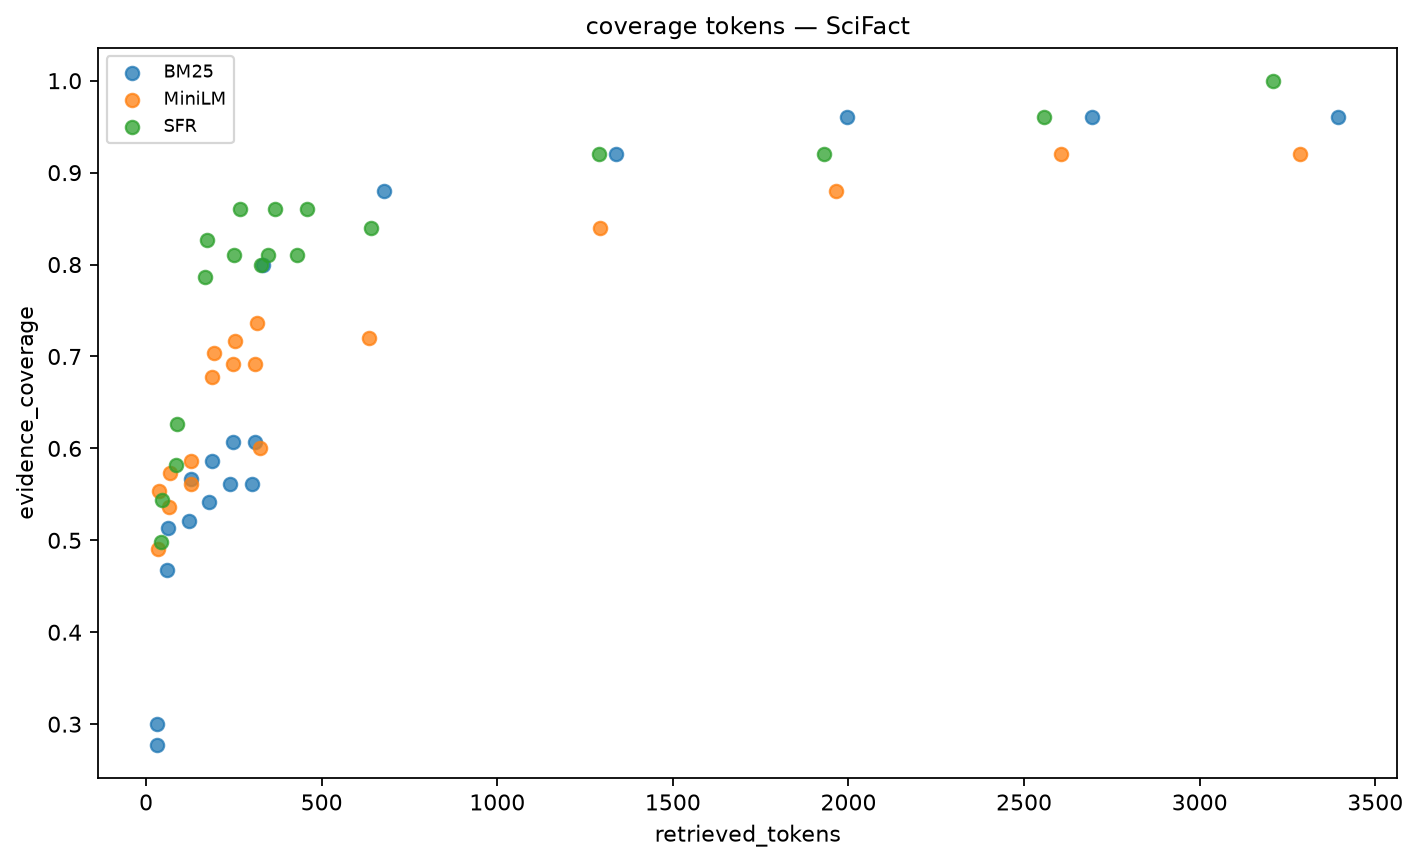

retriever_granularity HotpotQA


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,25.025793,1.0,0.00,0.72,NaN,...,2.66,0.811524,NaN,30.16,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
1,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,25.025793,2.0,0.12,0.82,0.883061,...,2.66,0.811524,0.116939,64.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
2,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,25.025793,4.0,0.36,0.92,0.888660,...,2.66,0.811524,0.111340,123.36,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
3,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,25.025793,6.0,0.52,0.96,0.903035,...,2.66,0.811524,0.096965,182.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
4,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,25.025793,8.0,0.62,0.98,0.904230,...,2.66,0.811524,0.095770,244.04,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
5,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,25.025793,10.0,0.68,1.00,0.909971,...,2.66,0.811524,0.090029,302.30,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
6,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,135.104,135.104000,1.0,0.00,0.86,NaN,...,2.66,0.921667,NaN,92.20,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
7,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,135.104,135.104000,2.0,0.36,0.96,0.866448,...,2.66,0.921667,0.133552,209.84,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
8,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,135.104,135.104000,4.0,0.66,1.00,0.882296,...,2.66,0.921667,0.117704,488.96,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
9,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,135.104,135.104000,6.0,0.80,1.00,0.884688,...,2.66,0.921667,0.115312,761.72,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50


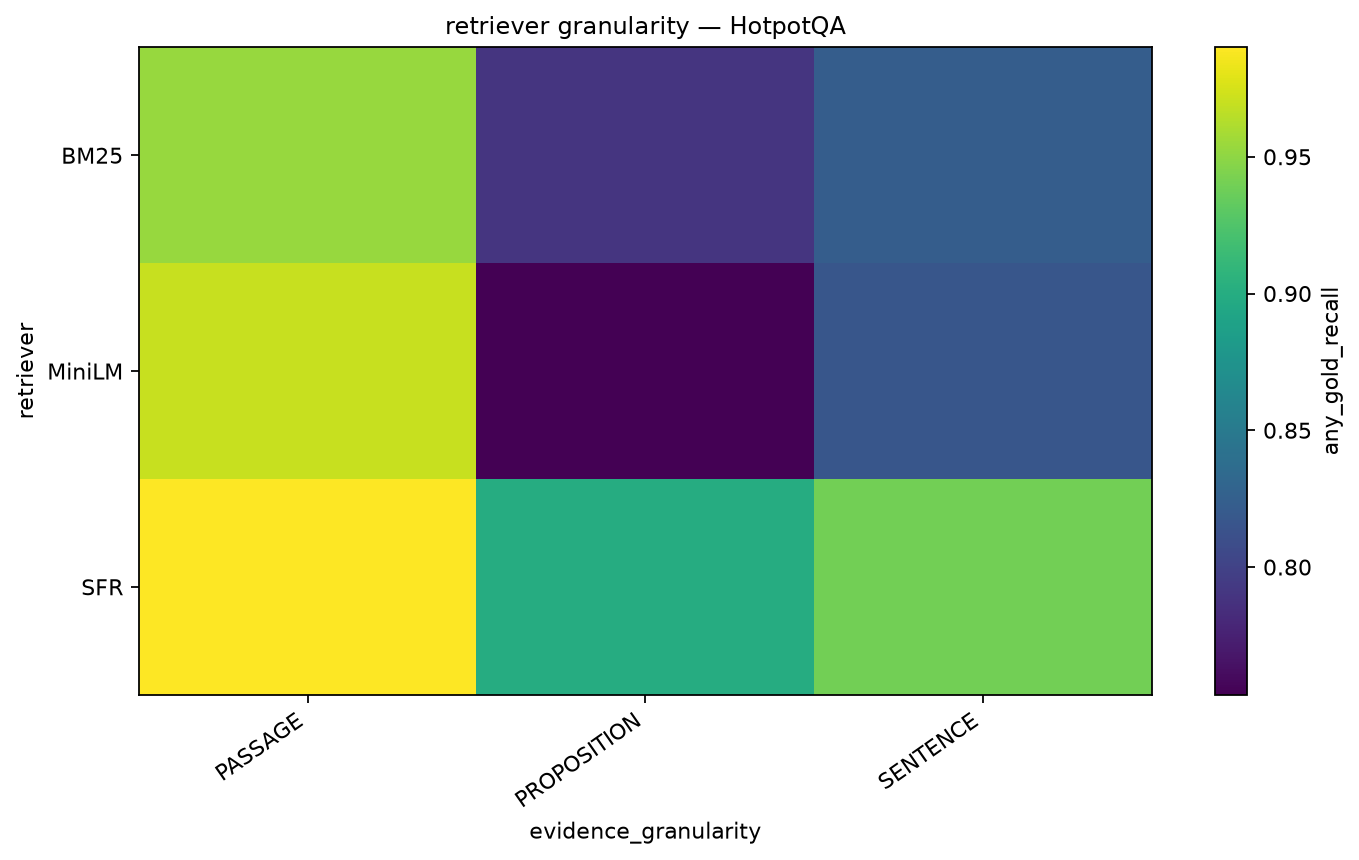

retriever_granularity QASPER


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,26.772315,1.00,0.000000,0.020833,NaN,...,1.56,0.044608,NaN,31.40,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
1,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,26.772315,2.00,0.000000,0.020833,0.879444,...,1.56,0.044608,0.120556,65.32,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
2,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,26.772315,4.00,0.000000,0.020833,0.887691,...,1.56,0.044608,0.112309,135.24,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
3,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,26.772315,6.00,0.000000,0.041667,0.898436,...,1.56,0.044608,0.101564,205.74,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
4,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,26.772315,8.00,0.000000,0.062500,0.900940,...,1.56,0.044608,0.099060,280.88,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
5,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,26.772315,10.00,0.000000,0.104167,0.905111,...,1.56,0.044608,0.094889,353.46,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
6,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,247.824398,247.824398,1.00,0.062500,0.125000,NaN,...,1.56,0.285101,NaN,249.36,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
7,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,247.824398,247.824398,2.00,0.125000,0.229167,0.856868,...,1.56,0.285101,0.143132,503.40,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
8,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,247.824398,247.824398,4.00,0.333333,0.458333,0.859456,...,1.56,0.285101,0.140544,1009.24,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
9,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,247.824398,247.824398,5.92,0.416667,0.479167,0.863586,...,1.56,0.285101,0.136414,1474.22,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48


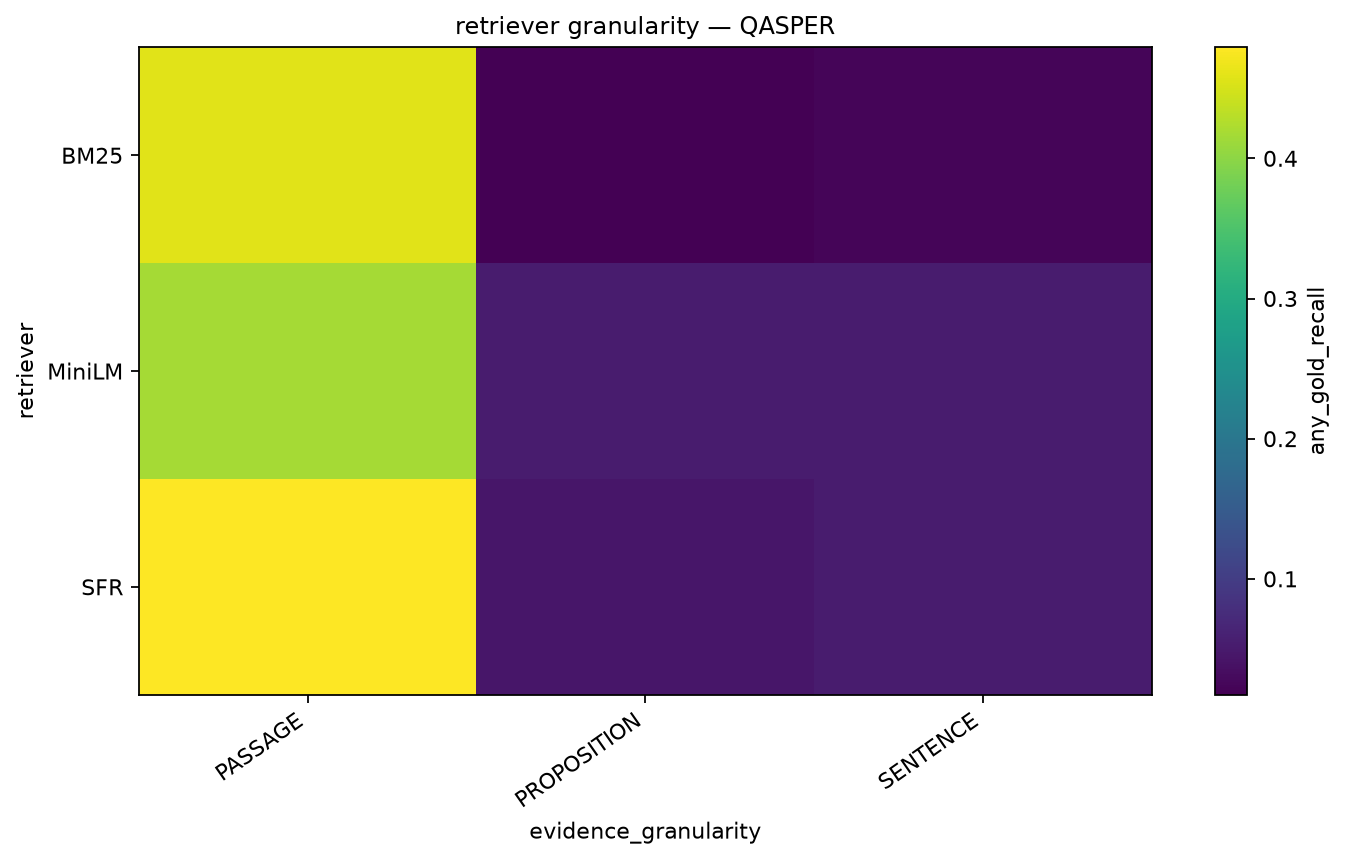

retriever_granularity SciFact


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,32.031467,1.0,0.32,0.60,NaN,...,0.8,0.697743,NaN,43.68,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
1,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,32.031467,2.0,0.40,0.68,0.881924,...,0.8,0.697743,0.118076,85.36,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
2,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,32.031467,4.0,0.60,0.88,0.897499,...,0.8,0.697743,0.102501,167.28,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
3,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,32.031467,6.0,0.68,0.88,0.908069,...,0.8,0.697743,0.091931,250.94,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
4,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,32.031467,8.0,0.68,0.88,0.915191,...,0.8,0.697743,0.084809,345.92,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
5,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,32.031467,10.0,0.68,0.88,0.916999,...,0.8,0.697743,0.083001,430.74,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
6,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,330.294231,330.294231,1.0,0.60,0.60,NaN,...,0.8,0.710200,NaN,325.02,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
7,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,330.294231,330.294231,2.0,0.72,0.72,0.903110,...,0.8,0.710200,0.096890,635.66,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
8,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,330.294231,330.294231,4.0,0.84,0.84,0.904100,...,0.8,0.710200,0.095900,1292.76,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
9,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,330.294231,330.294231,6.0,0.88,0.88,0.906847,...,0.8,0.710200,0.093153,1965.28,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25


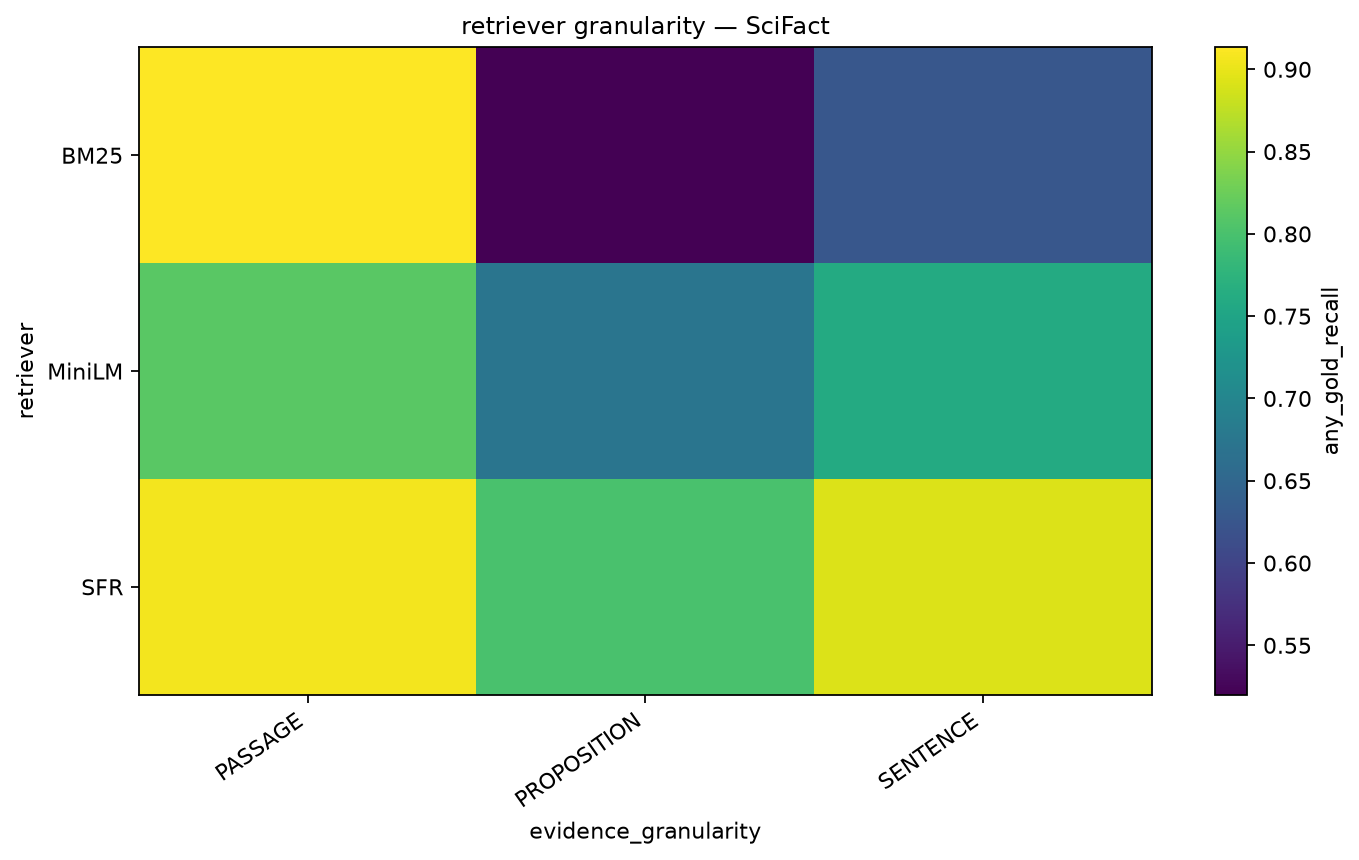

first_rank HotpotQA


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,bd4f9f7b6db5f1cc0603,5ae122465542997b2ef7d0f4,HotpotQA,SENTENCE,NaN,25.684211,P0,5ae122465542997b2ef7d0f4,BM25,False,10,0.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.125878,360,0,"['56c9ad5facead84a1c21492b36f7fcd2', 'c426f3b9aef0adad127ce9a0922a...",0.000284,NaN,NaN,NaN,NaN
1,55db50b68b85b4157276,5ab2f53d5542991669774157,HotpotQA,PROPOSITION,NaN,23.956522,P0,5ab2f53d5542991669774157,BM25,False,10,0.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.074489,272,0,"['eb6fff3714b9e370189bc30f0e7d38eb', 'b56ecae423c7480151d01e69c512...",0.000149,NaN,NaN,NaN,NaN
2,55db50b68b85b4157276,5a8ae00e5542992d82986fc7,HotpotQA,PROPOSITION,NaN,24.476190,P0,5a8ae00e5542992d82986fc7,BM25,False,10,0.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.097982,261,0,"['c86eb7dffc55c46569d1a15baf48f60d', '36f46ed2854d9bb7c1b1405fc823...",0.000214,NaN,NaN,NaN,NaN
3,aacff50085079bad87b8,5ae72fc5554299572ea54770,HotpotQA,PASSAGE,123.5,123.500000,P0,5ae72fc5554299572ea54770,SFR,False,10,1.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.286589,1235,0,"['5c2b263541bb74f3a7370dd911611ca9', '87a104a40c9b2aecc641ed094a96...",0.651817,0.568126,0.606041,0.041559,0.045326
4,69361abe8d8c0d1d61a8,5ab3b2fb554299753aec59af,HotpotQA,SENTENCE,NaN,25.557143,P0,5ab3b2fb554299753aec59af,SFR,False,10,1.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.109505,282,0,"['7b823e28429a87a866b56075cb231eff', '5361b94a97684ce199b32d72898b...",2.401208,2.815110,2.400367,0.041362,0.000081
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,a5ccd1b17003da385cf5,5ac02c4a5542992a796decbd,HotpotQA,PROPOSITION,NaN,22.194805,P0,5ac02c4a5542992a796decbd,MiniLM,False,10,0.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,0.2,0.063024,294,0,"['736db368a7d97d186cf74a93dc3a9bcc', '03d2257e29c218c200bba6fdcb8e...",0.646452,0.608444,0.645445,0.007571,0.000109
446,69361abe8d8c0d1d61a8,5ae1b943554299492dc91b7f,HotpotQA,SENTENCE,NaN,26.680000,P0,5ae1b943554299492dc91b7f,SFR,False,10,1.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.067181,286,0,"['22dcfa98607c4b774e32ebf91b3f3df4', '3753fa89e6ae496ab5bfdd7cce4c...",2.223103,2.028266,2.222470,0.040972,0.000077
447,0bc6111c85ee7f5f4a69,5a722c2255429971e9dc932c,HotpotQA,PASSAGE,126.5,126.500000,P0,5a722c2255429971e9dc932c,MiniLM,False,10,1.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.126567,1265,0,"['a9cdf026c391d41e2a76f0f02a2b91d1', 'e6d0722cf2921990f6cf96c1defb...",0.160567,0.111130,0.149725,0.007502,0.010706
448,0bc6111c85ee7f5f4a69,5ae122465542997b2ef7d0f4,HotpotQA,PASSAGE,98.2,98.200000,P0,5ae122465542997b2ef7d0f4,MiniLM,False,10,1.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.127028,982,0,"['905d1877aef1fa3ad14ea152f3d90bbe', 'eec31891255210a54351cd12313c...",0.159463,0.115093,0.149977,0.006618,0.009357


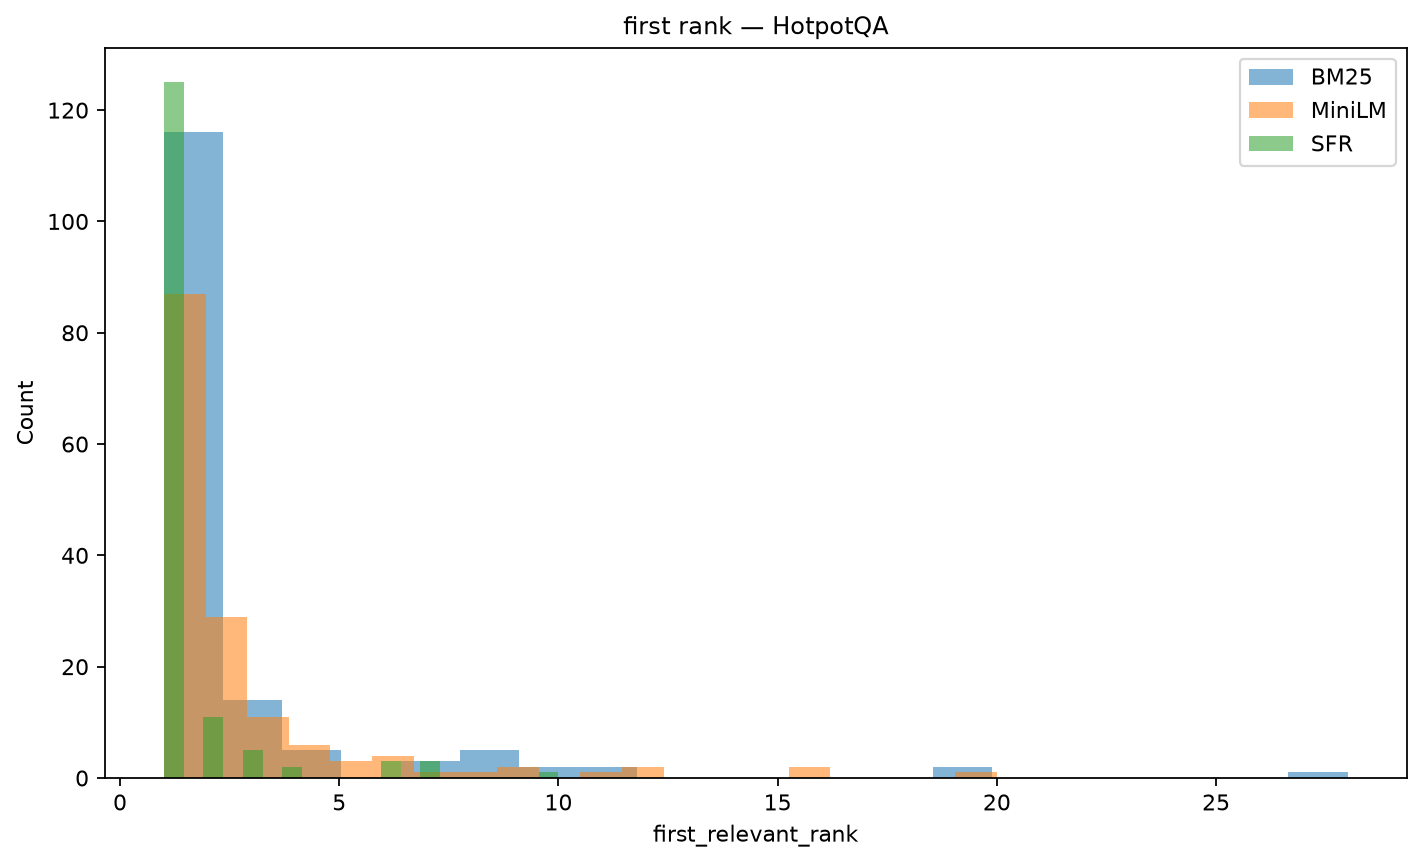

first_rank QASPER


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,08eeaf51742df28d788e,591,QASPER,PROPOSITION,NaN,29.657143,P0,1801,SFR,False,10,0.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,0.007463,0.092726,468,0,"['0c264317015608e2b5abcdf1b218294d', 'c723314be6eeffec7a4b11637d1c...",1.415431,8.523570,1.413088,0.041312,0.000066
1,a5ccd1b17003da385cf5,394,QASPER,PROPOSITION,NaN,32.069869,P0,1283,MiniLM,False,10,0.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,0.009804,0.081247,260,0,"['517805d720dcbde6b31969e2797963aa', 'fa987bc0007b6a3fa1810c899abe...",0.176114,1.694359,0.175111,0.006812,0.000049
2,55db50b68b85b4157276,252,QASPER,PROPOSITION,NaN,28.077626,P0,879,BM25,False,10,0.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,0.009615,0.094672,248,0,"['1987c0744f1f897e00bba4d5494b1790', 'c868dc87f209e453a445f2db7f1f...",0.000732,NaN,NaN,NaN,NaN
3,43db754dc48ca3463c07,467,QASPER,SENTENCE,NaN,24.875000,P0,1496,MiniLM,False,10,0.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,0.000000,0.060939,278,1,"['bf0e9bede56681f47a7b4a8eeb4a1e6d', '56baf71adc50a73b951f8fae5d3b...",0.002170,0.341079,0.001929,0.008893,0.000047
4,0bc6111c85ee7f5f4a69,45,QASPER,PASSAGE,245.409091,245.409091,P0,155,MiniLM,False,10,0.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,0.090909,0.121776,2556,0,"['98b0317837656f910e37d34d37c1f1bb', '56e73b57a1b2bdcc57d44e495efe...",3.552184,0.466029,3.537660,0.010361,0.014325
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,aacff50085079bad87b8,110,QASPER,PASSAGE,246.555556,246.555556,P0,420,SFR,False,10,1.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,0.500000,0.129857,2395,0,"['13950f5d6d54aeb6b854a449051193d5', 'd30e94c2499cd44e269fe1552284...",1.974552,1.853870,1.929681,0.040790,0.044506
446,a5ccd1b17003da385cf5,665,QASPER,PROPOSITION,NaN,26.750000,P0,1964,MiniLM,False,10,NaN,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.114128,276,0,"['ed4eb3ad09f47a925f56582110bc3ba3', 'b78b940895aab83eb78d127d6c5e...",0.005651,0.983131,0.005141,0.006866,0.000057
447,aacff50085079bad87b8,591,QASPER,PASSAGE,249.040000,249.040000,P0,1801,SFR,False,10,1.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,0.200000,0.131664,2557,0,"['3dad317670696db1625b68889ea40a25', 'ef98d6d02b8de5601846202d284b...",2.786015,2.626962,2.740685,0.041312,0.044824
448,bd4f9f7b6db5f1cc0603,203,QASPER,SENTENCE,NaN,28.989583,P0,737,BM25,False,10,0.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,0.010753,0.067403,191,0,"['410414f3579fd7393fbb818fd4760c73', '22d39d8fd6dc489f70bd00d00d7d...",0.000285,NaN,NaN,NaN,NaN


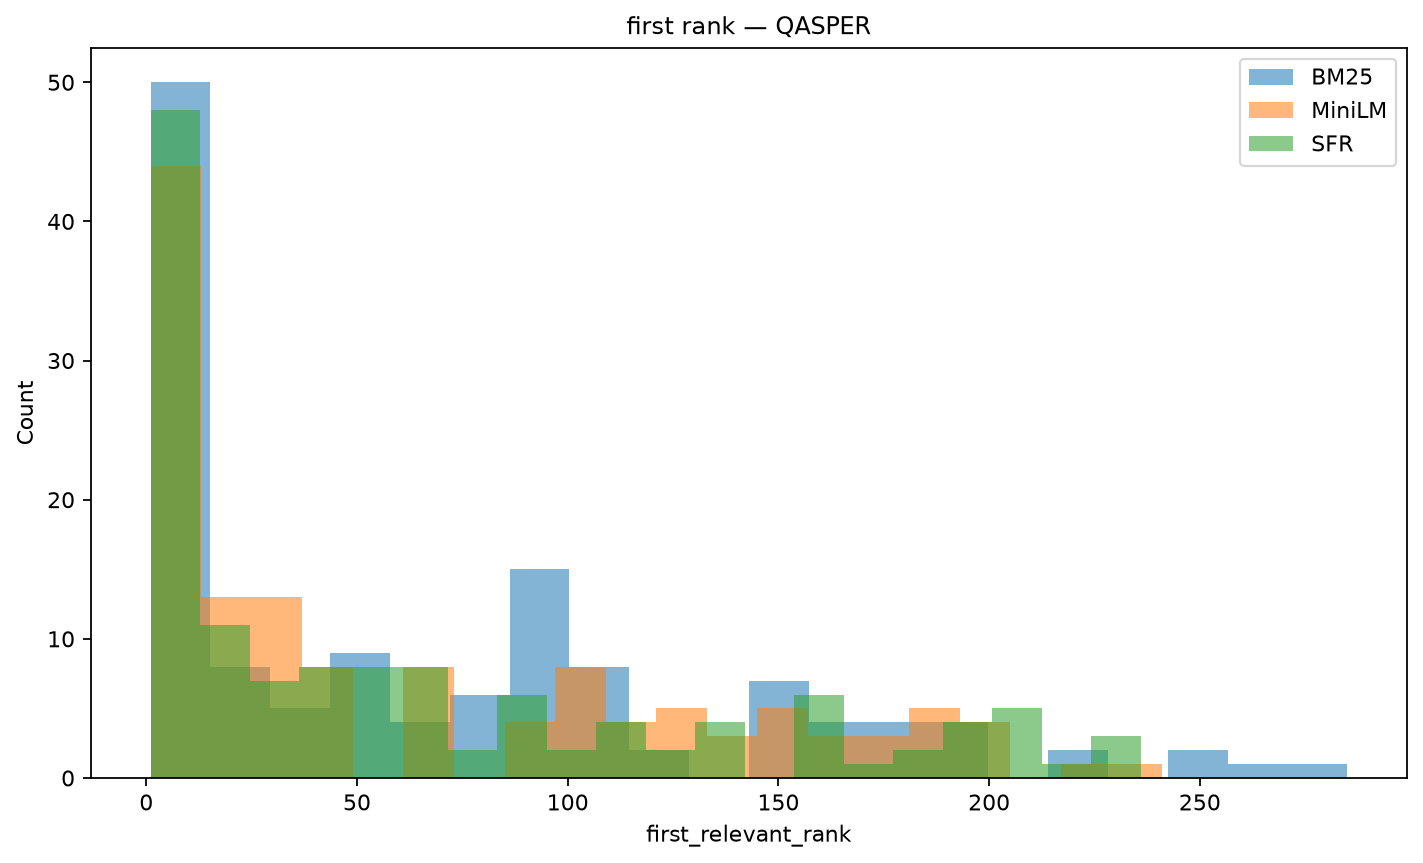

first_rank SciFact


,action_id,cluster_id,dataset,evidence_granularity,mean_passage_tokens,mean_unit_tokens,passage_representation,query_id,retriever,synthetic,actual_k,all_gold_recall,...,k,mapping_note,mrr,redundancy,retrieved_tokens,unmapped_gold,top_ids,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds
0,0bc6111c85ee7f5f4a69,312,SciFact,PASSAGE,330.294231,330.294231,P0,312,MiniLM,False,10,NaN,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.096906,2747,0,"['ab8308428a5c066294c16615563fd61d', '8dcc25b3b09b31548a8f013a0126...",0.210245,114.823021,0.170868,0.008024,0.012646
1,0bc6111c85ee7f5f4a69,1232,SciFact,PASSAGE,330.294231,330.294231,P0,1232,MiniLM,False,10,1.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.108083,3243,0,"['8a50a6ebb63b4ea2f0edbb76b27bfdaf', '76555d05d49ee751a2d0fcda1168...",0.213455,114.823021,0.171472,0.011912,0.015362
2,a5ccd1b17003da385cf5,384,SciFact,PROPOSITION,NaN,32.031467,P0,384,MiniLM,False,10,NaN,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.064928,324,0,"['f98d17432a61623d4af8d34f4dc5f11b', 'b6a0f2d3c8c00de83ad053bcd768...",1.572836,394.256102,1.274801,0.012649,0.001096
3,0bc6111c85ee7f5f4a69,1107,SciFact,PASSAGE,330.294231,330.294231,P0,1107,MiniLM,False,10,1.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,0.5,0.105555,2887,0,"['320a57b1ca7c35803ce6a24bb38eb1a9', '9824c50783842c4cbc150a65c836...",0.220084,114.823021,0.175377,0.007975,0.018102
4,08eeaf51742df28d788e,384,SciFact,PROPOSITION,NaN,32.031467,P0,384,SFR,False,10,NaN,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.070728,524,0,"['f680f4f553a1770096f1d1244e55d213', '4eaab8c516e99213130ea63ae86e...",2.574028,2194.186446,1.867826,0.060993,0.001479
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,a5ccd1b17003da385cf5,440,SciFact,PROPOSITION,NaN,32.031467,P0,440,MiniLM,False,10,NaN,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.097707,381,0,"['40de997dc2a823ac3537b3b2b0476b91', '84b70c73d70d9d87af538956d7d1...",1.568365,394.256102,1.272745,0.008799,0.001109
446,55db50b68b85b4157276,517,SciFact,PROPOSITION,NaN,32.031467,P0,517,BM25,False,10,NaN,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.117246,278,0,"['dc40bf8034575540ad383483c8b3f716', '247ce85ee1a87dcb0ecd6a7c28ae...",0.235727,NaN,NaN,NaN,NaN
447,a5ccd1b17003da385cf5,820,SciFact,PROPOSITION,NaN,32.031467,P0,820,MiniLM,False,10,NaN,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,NaN,0.064388,207,0,"['dc292893cfa30bab3225f38416380725', '6a8c3754c8256ecdbc63ecf6e947...",1.561414,394.256102,1.262750,0.007373,0.001063
448,08eeaf51742df28d788e,1024,SciFact,PROPOSITION,NaN,32.031467,P0,1024,SFR,False,10,1.0,...,10,Full non-whitespace annotated-character union coverage; repeated Q...,1.0,0.105966,472,0,"['1a9904a3f0018d691c0feb28f8731bee', '05e95ced35d0ad8a3d15aa39e1cc...",2.538886,2194.186446,1.820589,0.057639,0.001527


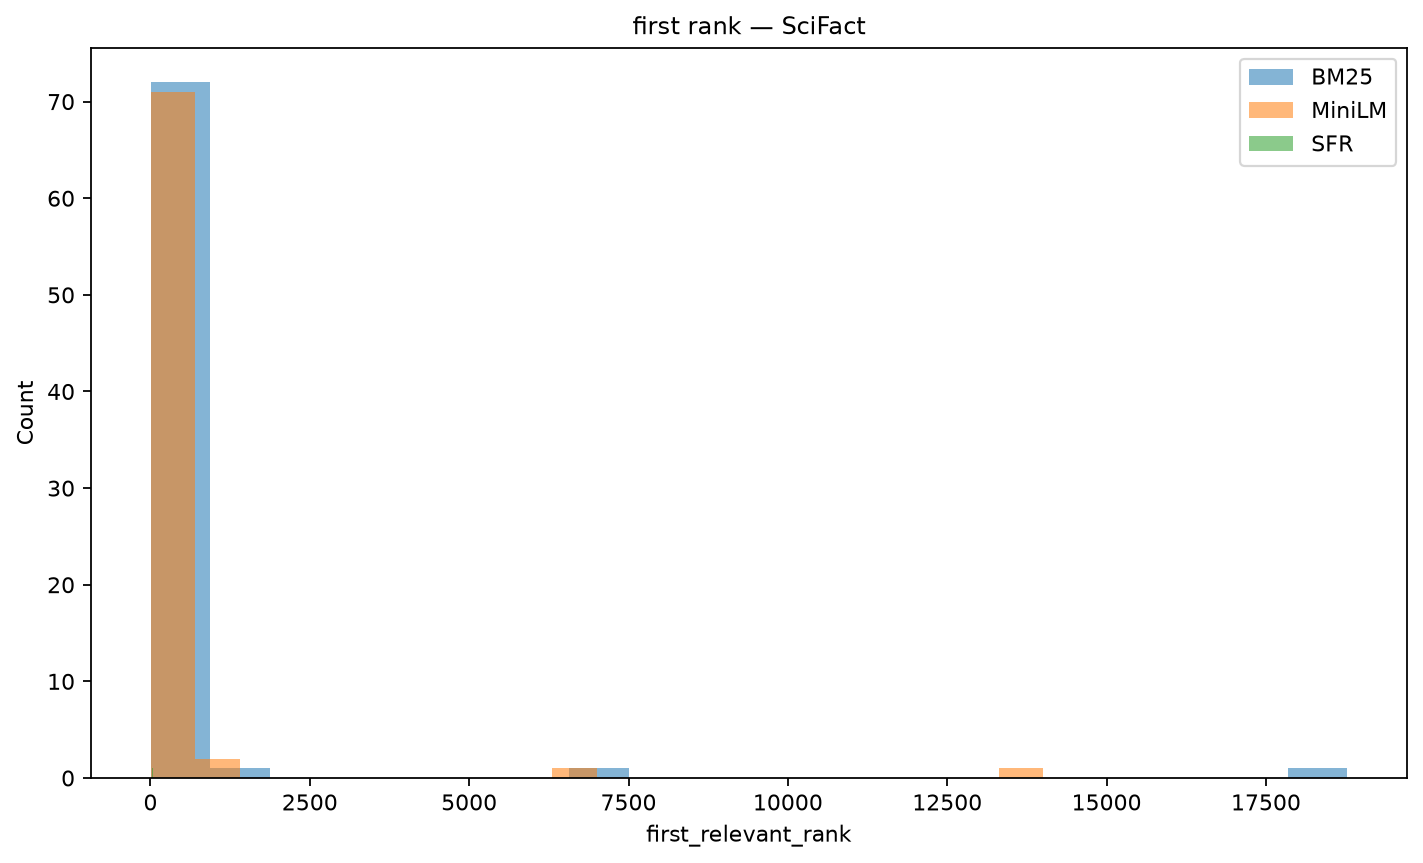

redundancy HotpotQA


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,25.025793,1.0,0.00,0.72,NaN,...,2.66,0.811524,NaN,30.16,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
1,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,25.025793,2.0,0.12,0.82,0.883061,...,2.66,0.811524,0.116939,64.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
2,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,25.025793,4.0,0.36,0.92,0.888660,...,2.66,0.811524,0.111340,123.36,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
3,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,25.025793,6.0,0.52,0.96,0.903035,...,2.66,0.811524,0.096965,182.18,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
4,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,25.025793,8.0,0.62,0.98,0.904230,...,2.66,0.811524,0.095770,244.04,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
5,HotpotQA,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,25.025793,10.0,0.68,1.00,0.909971,...,2.66,0.811524,0.090029,302.30,0.0,1.526264,2.127114,1.525387,0.041409,0.000129,50,50
6,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,135.104,135.104000,1.0,0.00,0.86,NaN,...,2.66,0.921667,NaN,92.20,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
7,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,135.104,135.104000,2.0,0.36,0.96,0.866448,...,2.66,0.921667,0.133552,209.84,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
8,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,135.104,135.104000,4.0,0.66,1.00,0.882296,...,2.66,0.921667,0.117704,488.96,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50
9,HotpotQA,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,135.104,135.104000,6.0,0.80,1.00,0.884688,...,2.66,0.921667,0.115312,761.72,0.0,0.170901,0.123424,0.159961,0.007287,0.010782,50,50


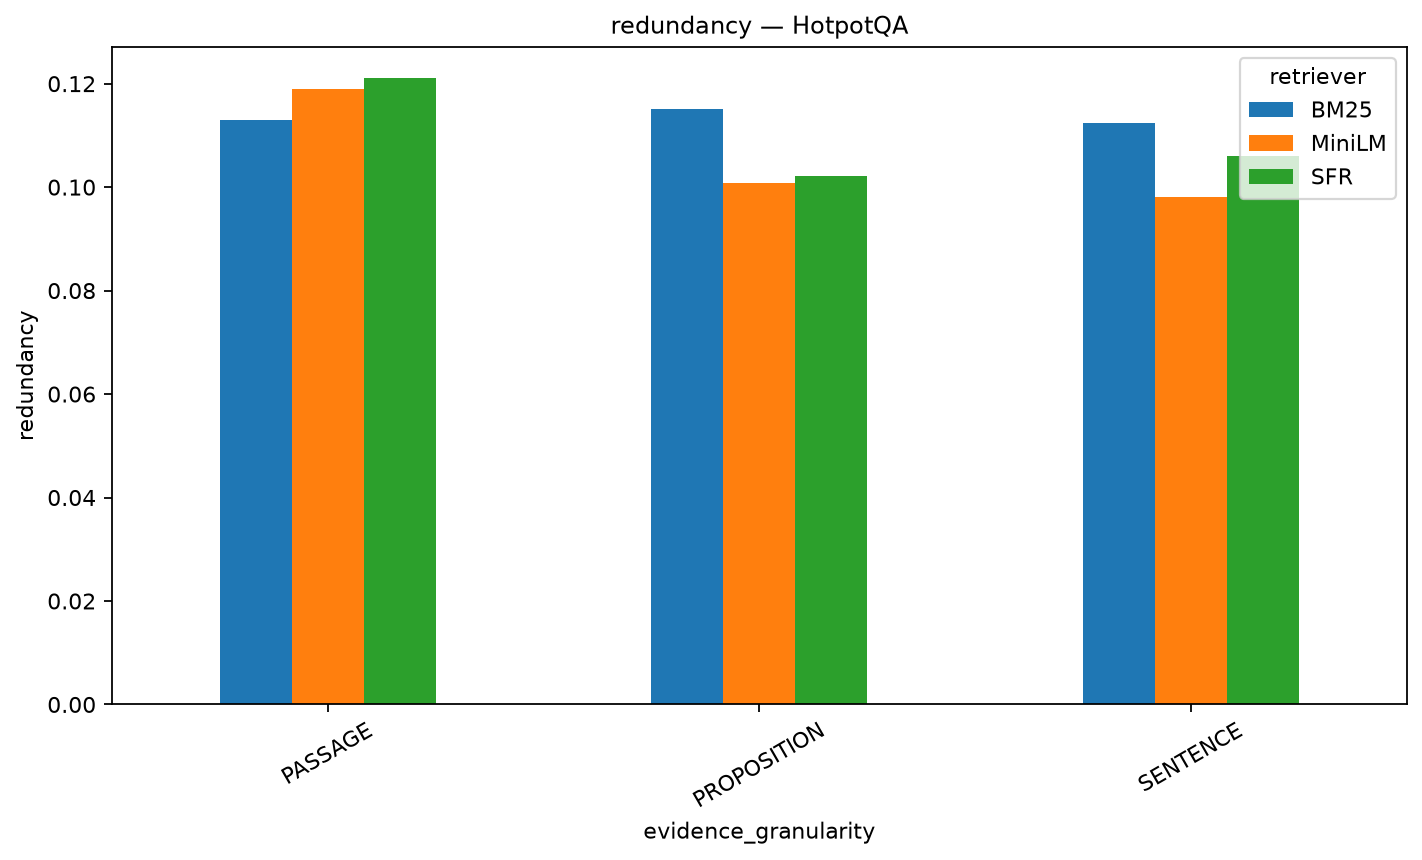

redundancy QASPER


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,26.772315,1.00,0.000000,0.020833,NaN,...,1.56,0.044608,NaN,31.40,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
1,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,26.772315,2.00,0.000000,0.020833,0.879444,...,1.56,0.044608,0.120556,65.32,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
2,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,26.772315,4.00,0.000000,0.020833,0.887691,...,1.56,0.044608,0.112309,135.24,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
3,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,26.772315,6.00,0.000000,0.041667,0.898436,...,1.56,0.044608,0.101564,205.74,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
4,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,26.772315,8.00,0.000000,0.062500,0.900940,...,1.56,0.044608,0.099060,280.88,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
5,QASPER,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,26.772315,10.00,0.000000,0.104167,0.905111,...,1.56,0.044608,0.094889,353.46,0.16,0.377070,7.401362,0.375101,0.042114,0.000082,50,48
6,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,247.824398,247.824398,1.00,0.062500,0.125000,NaN,...,1.56,0.285101,NaN,249.36,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
7,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,247.824398,247.824398,2.00,0.125000,0.229167,0.856868,...,1.56,0.285101,0.143132,503.40,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
8,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,247.824398,247.824398,4.00,0.333333,0.458333,0.859456,...,1.56,0.285101,0.140544,1009.24,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48
9,QASPER,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,247.824398,247.824398,5.92,0.416667,0.479167,0.863586,...,1.56,0.285101,0.136414,1474.22,0.16,0.524311,0.416139,0.511202,0.007375,0.012909,50,48


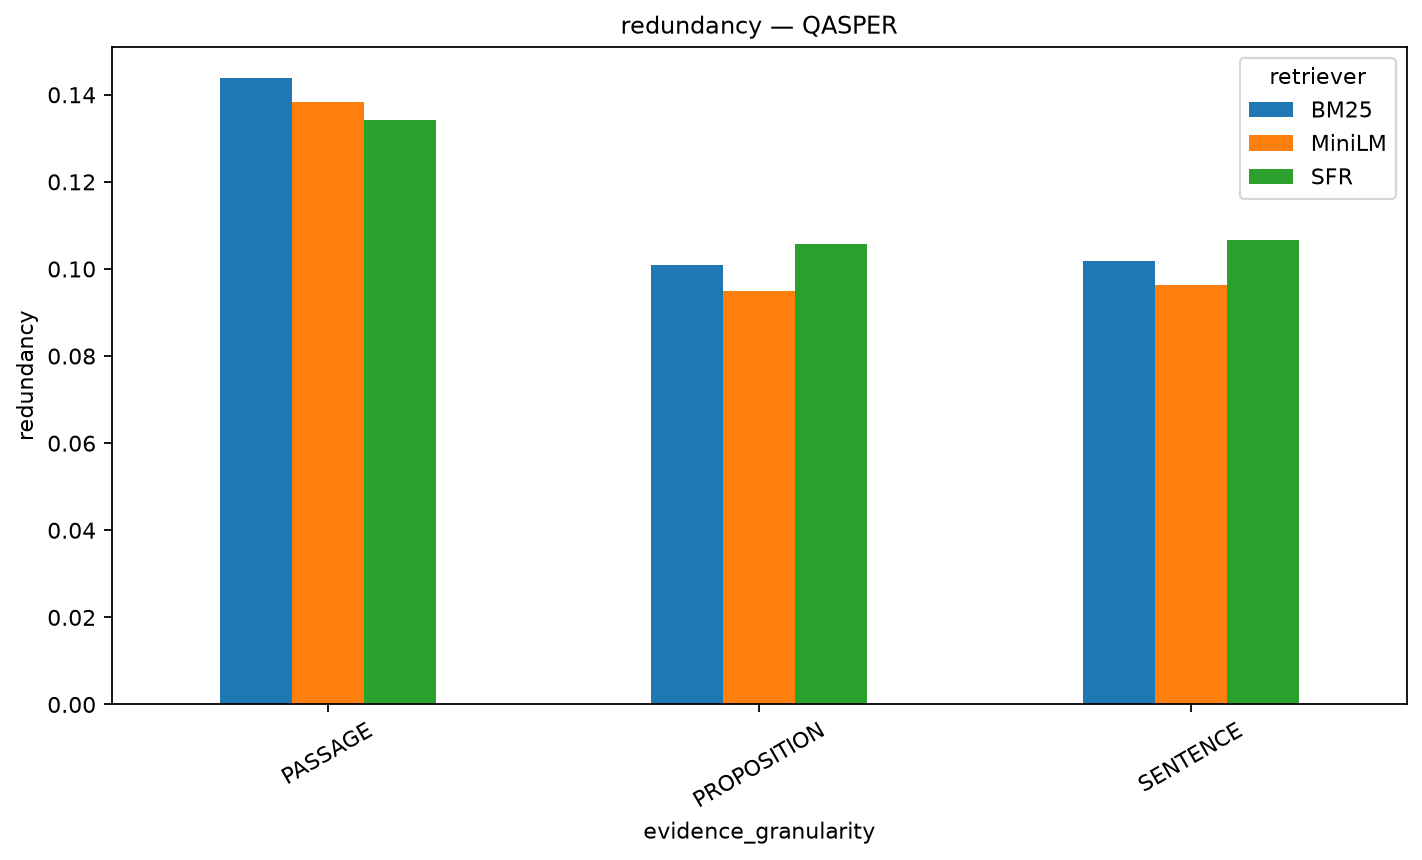

redundancy SciFact


,dataset,action_id,retriever,evidence_granularity,passage_representation,k,mean_passage_tokens,mean_unit_tokens,actual_k,all_gold_recall,any_gold_recall,candidate_diversity,...,gold_annotation_count,mrr,redundancy,retrieved_tokens,unmapped_gold,retrieval_latency,document_preprocessing_original_seconds,document_embedding_lookup_seconds,query_embedding_original_seconds,query_embedding_lookup_seconds,n_queries,gold_metric_denominator
0,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,1,NaN,32.031467,1.0,0.32,0.60,NaN,...,0.8,0.697743,NaN,43.68,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
1,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,2,NaN,32.031467,2.0,0.40,0.68,0.881924,...,0.8,0.697743,0.118076,85.36,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
2,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,4,NaN,32.031467,4.0,0.60,0.88,0.897499,...,0.8,0.697743,0.102501,167.28,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
3,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,6,NaN,32.031467,6.0,0.68,0.88,0.908069,...,0.8,0.697743,0.091931,250.94,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
4,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,8,NaN,32.031467,8.0,0.68,0.88,0.915191,...,0.8,0.697743,0.084809,345.92,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
5,SciFact,08eeaf51742df28d788e,SFR,PROPOSITION,P0,10,NaN,32.031467,10.0,0.68,0.88,0.916999,...,0.8,0.697743,0.083001,430.74,0.0,9.877243,2194.186446,9.056582,0.058019,0.001471,50,25
6,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,1,330.294231,330.294231,1.0,0.60,0.60,NaN,...,0.8,0.710200,NaN,325.02,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
7,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,2,330.294231,330.294231,2.0,0.72,0.72,0.903110,...,0.8,0.710200,0.096890,635.66,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
8,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,4,330.294231,330.294231,4.0,0.84,0.84,0.904100,...,0.8,0.710200,0.095900,1292.76,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25
9,SciFact,0bc6111c85ee7f5f4a69,MiniLM,PASSAGE,P0,6,330.294231,330.294231,6.0,0.88,0.88,0.906847,...,0.8,0.710200,0.093153,1965.28,0.0,2.994194,114.823021,2.954385,0.008658,0.012577,50,25


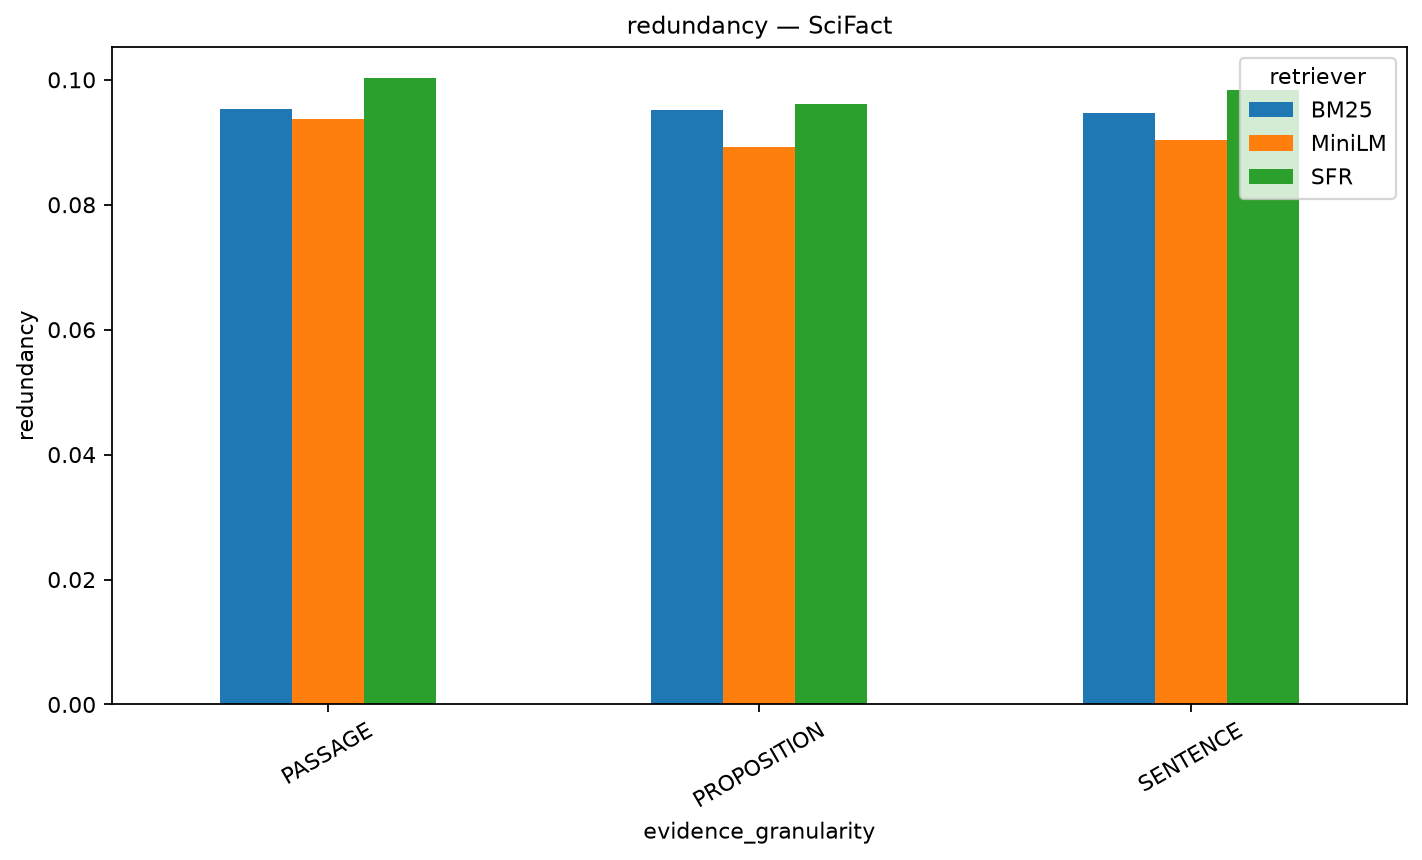

In [9]:
for figure in figures:
    print(figure['name'], figure['dataset'])
    display(pd.read_csv(figure['data']))
    display(Image(filename=figure['png']))
if not figures: print('No completed data for these plots yet; no fabricated values were substituted.')


## Manual review / freeze

After inspecting real completed results, edit the review fields in the first FLAGS cell. Set `REVIEW_PHASE` to this phase, `REVIEWED_CONFIG` to a dictionary, and give a rationale. No winning setting is chosen automatically. Smoke cannot be frozen. If optional conditions remain pending, list them explicitly in `REVIEWED_CONFIG["waive_pending"]`, or qualify them before running.

In [10]:
if REVIEW_PHASE is not None:
    if RUN_SMOKE: raise ValueError('Cannot freeze fabricated smoke output')
    if REVIEW_PHASE != 'A': raise ValueError('Review this notebook phase only')
    display(review(cfg, REVIEW_PHASE, REVIEWED_CONFIG, REVIEW_REASON))
else:
    print('Review not requested. No downstream configuration was selected automatically.')
display(status(cfg))


Review not requested. No downstream configuration was selected automatically.


,phase,notebook,full_status,number_expected,number_completed,result_path,next_action,freeze_exists
0,0,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,150.0,150,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
1,A,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,1350.0,1350,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
2,B,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,600.0,600,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
3,C,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE_ELIGIBLE_PENDING_OPTIONAL,5550.0,5550,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,False
4,D,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
5,E,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
6,F,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
7,G,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
8,H,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
9,I,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
